In [21]:
# Import core libraries
import os
import numpy as np
import pandas as pd
from glob import glob

# Data Preprocessing
from sklearn.preprocessing import MinMaxScaler

# ML Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Visualization (Optional: can be added later)
import matplotlib.pyplot as plt

# Path to the data folder containing 50 company CSVs
data_folder = "NIFTY50-Data"
csv_files = glob(os.path.join(data_folder, "*.csv"))
print(f"Found {len(csv_files)} company files.")


Found 50 company files.


In [23]:
import os
import pandas as pd
from glob import glob

data_folder = "NIFTY50-Data"
csv_files = glob(os.path.join(data_folder, "*.csv"))

for file in csv_files:
    # Read all lines
    with open(file, 'r') as f:
        lines = f.readlines()
    # Remove any row where the first column is 'Ticker' or 'Date' (case-insensitive)
    cleaned_lines = []
    for line in lines:
        first_col = line.strip().split(',')[0].strip().lower()
        if first_col not in ['ticker', 'date']:
            cleaned_lines.append(line)
    # Save the cleaned lines to a temporary file
    temp_file = file + "_tmp"
    with open(temp_file, 'w') as f:
        f.writelines(cleaned_lines)
    # Read cleaned data into DataFrame
    df = pd.read_csv(temp_file)
    os.remove(temp_file)
    # Rename 'Price' column to 'Date' if present
    df.rename(columns={'Price': 'Date'}, inplace=True)
    # Normalize column names (capitalize for matching)
    df.columns = [col.strip().capitalize() for col in df.columns]
    # Only keep the required columns, in order
    columns_required = ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']
    df = df[columns_required]
    # Save back to CSV (overwrite original)
    df.to_csv(file, index=False)
    print(f"Fixed: {os.path.basename(file)}")

print("\nAll files cleaned and fixed as per your requirements!")


Fixed: ADANIENT.NS_2018_2023.csv
Fixed: ADANIPORTS.NS_2018_2023.csv
Fixed: APOLLOHOSP.NS_2018_2023.csv
Fixed: ASIANPAINT.NS_2018_2023.csv
Fixed: AXISBANK.NS_2018_2023.csv
Fixed: BAJAJ-AUTO.NS_2018_2023.csv
Fixed: BAJAJFINSV.NS_2018_2023.csv
Fixed: BAJFINANCE.NS_2018_2023.csv
Fixed: BEL.NS_2018_2023.csv
Fixed: BHARTIARTL.NS_2018_2023.csv
Fixed: CIPLA.NS_2018_2023.csv
Fixed: COALINDIA.NS_2018_2023.csv
Fixed: DRREDDY.NS_2018_2023.csv
Fixed: EICHERMOT.NS_2018_2023.csv
Fixed: ETERNAL.NS_2018_2023.csv
Fixed: GRASIM.NS_2018_2023.csv
Fixed: HCLTECH.NS_2018_2023.csv
Fixed: HDFCBANK.NS_2018_2023.csv
Fixed: HDFCLIFE.NS_2018_2023.csv
Fixed: HEROMOTOCO.NS_2018_2023.csv
Fixed: HINDALCO.NS_2018_2023.csv
Fixed: HINDUNILVR.NS_2018_2023.csv
Fixed: ICICIBANK.NS_2018_2023.csv
Fixed: INDUSINDBK.NS_2018_2023.csv
Fixed: INFY.NS_2018_2023.csv
Fixed: ITC.NS_2018_2023.csv
Fixed: JIOFIN.NS_2018_2023.csv
Fixed: JSWSTEEL.NS_2018_2023.csv
Fixed: KOTAKBANK.NS_2018_2023.csv
Fixed: LT.NS_2018_2023.csv
Fixed: M&M.NS_20

In [30]:
import os
import pandas as pd
from glob import glob

data_folder = "NIFTY50-Data"
csv_files = glob(os.path.join(data_folder, "*.csv"))

for file in csv_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
    df = df.sort_values('Date').reset_index(drop=True)
    print(f"\n[{company_name}] Missing values : \n{df.isnull().sum()}")



[ADANIENT.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[ADANIPORTS.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[APOLLOHOSP.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[ASIANPAINT.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[AXISBANK.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[BAJAJ-AUTO.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[BAJAJFINSV.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[BAJFINANCE.NS] Missing values : 
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

[BEL.NS] Missing values : 
Date      0
Clos

In [32]:
import os
import pandas as pd
from glob import glob
from sklearn.preprocessing import MinMaxScaler

data_folder = "NIFTY50-Data"
csv_files = glob(os.path.join(data_folder, "*.csv"))

normalized_data = {}

for file in csv_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
    df = df.sort_values('Date').reset_index(drop=True)
    
    numeric_cols = ['Close', 'High', 'Low', 'Open', 'Volume']
    
    # Only normalize if DataFrame is not empty
    if len(df) > 0:
        scaler = MinMaxScaler()
        df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
        normalized_data[company_name] = df
        print(f"Normalized: {company_name}")
    else:
        print(f"Skipped {company_name} (empty DataFrame)")

print("\nMinMax normalization completed for all companies.")


Normalized: ADANIENT.NS
Normalized: ADANIPORTS.NS
Normalized: APOLLOHOSP.NS
Normalized: ASIANPAINT.NS
Normalized: AXISBANK.NS
Normalized: BAJAJ-AUTO.NS
Normalized: BAJAJFINSV.NS
Normalized: BAJFINANCE.NS
Normalized: BEL.NS
Normalized: BHARTIARTL.NS
Normalized: CIPLA.NS
Normalized: COALINDIA.NS
Normalized: DRREDDY.NS
Normalized: EICHERMOT.NS
Skipped ETERNAL.NS (empty DataFrame)
Normalized: GRASIM.NS
Normalized: HCLTECH.NS
Normalized: HDFCBANK.NS
Normalized: HDFCLIFE.NS
Normalized: HEROMOTOCO.NS
Normalized: HINDALCO.NS
Normalized: HINDUNILVR.NS
Normalized: ICICIBANK.NS
Normalized: INDUSINDBK.NS
Normalized: INFY.NS
Normalized: ITC.NS
Normalized: JIOFIN.NS
Normalized: JSWSTEEL.NS
Normalized: KOTAKBANK.NS
Normalized: LT.NS
Normalized: M&M.NS
Normalized: MARUTI.NS
Normalized: NESTLEIND.NS
Normalized: NTPC.NS
Normalized: ONGC.NS
Normalized: POWERGRID.NS
Normalized: RELIANCE.NS
Normalized: SBILIFE.NS
Normalized: SBIN.NS
Normalized: SHRIRAMFIN.NS
Normalized: SUNPHARMA.NS
Normalized: TATACONSUM.

In [33]:
import os
import numpy as np

# Helper functions
def calculate_rsi(series, window=14):
    delta = series.diff()
    gain = (delta.clip(lower=0)).rolling(window=window).mean()
    loss = (-delta.clip(upper=0)).rolling(window=window).mean()
    rs = gain / (loss + 1e-10)
    return 100 - (100 / (1 + rs))

def calculate_macd(series, fast=12, slow=26, signal=9):
    exp1 = series.ewm(span=fast, adjust=False).mean()
    exp2 = series.ewm(span=slow, adjust=False).mean()
    macd = exp1 - exp2
    signal_line = macd.ewm(span=signal, adjust=False).mean()
    return macd, signal_line

# Ensure the output directory exists
engineered_folder = "engineered"
os.makedirs(engineered_folder, exist_ok=True)

for company, df in normalized_data.items():
    df = df.copy()
    # SMA
    df['SMA10'] = df['Close'].rolling(window=10).mean()
    df['SMA50'] = df['Close'].rolling(window=50).mean()
    df['SMA200'] = df['Close'].rolling(window=200).mean()
    # EMA
    df['EMA10'] = df['Close'].ewm(span=10, adjust=False).mean()
    df['EMA50'] = df['Close'].ewm(span=50, adjust=False).mean()
    df['EMA200'] = df['Close'].ewm(span=200, adjust=False).mean()
    # RSI
    df['RSI14'] = calculate_rsi(df['Close'], window=14)
    # MACD & Signal
    macd, signal = calculate_macd(df['Close'])
    df['MACD'] = macd
    df['MACD_Signal'] = signal
    # Drop rows with any NaN (optional, only if you want to train models directly after)
    df = df.dropna().reset_index(drop=True)
    # Save to engineered folder
    out_path = os.path.join(engineered_folder, f"{company}_engineered.csv")
    df.to_csv(out_path, index=False)
    print(f"Engineered & saved: {out_path}")

print("\nFeature engineering complete for all companies! Files are in the 'engineered' folder.")


Engineered & saved: engineered\ADANIENT.NS_engineered.csv
Engineered & saved: engineered\ADANIPORTS.NS_engineered.csv
Engineered & saved: engineered\APOLLOHOSP.NS_engineered.csv
Engineered & saved: engineered\ASIANPAINT.NS_engineered.csv
Engineered & saved: engineered\AXISBANK.NS_engineered.csv
Engineered & saved: engineered\BAJAJ-AUTO.NS_engineered.csv
Engineered & saved: engineered\BAJAJFINSV.NS_engineered.csv
Engineered & saved: engineered\BAJFINANCE.NS_engineered.csv
Engineered & saved: engineered\BEL.NS_engineered.csv
Engineered & saved: engineered\BHARTIARTL.NS_engineered.csv
Engineered & saved: engineered\CIPLA.NS_engineered.csv
Engineered & saved: engineered\COALINDIA.NS_engineered.csv
Engineered & saved: engineered\DRREDDY.NS_engineered.csv
Engineered & saved: engineered\EICHERMOT.NS_engineered.csv
Engineered & saved: engineered\GRASIM.NS_engineered.csv
Engineered & saved: engineered\HCLTECH.NS_engineered.csv
Engineered & saved: engineered\HDFCBANK.NS_engineered.csv
Engineered

In [34]:
import os
import pandas as pd
from glob import glob

engineered_folder = "engineered"
train_folder = "train_split"
test_folder = "test_split"

os.makedirs(train_folder, exist_ok=True)
os.makedirs(test_folder, exist_ok=True)

engineered_files = glob(os.path.join(engineered_folder, "*_engineered.csv"))

for file in engineered_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    # Ensure sorted by date (for time series)
    df = df.sort_values('Date').reset_index(drop=True)
    # 80% train, 20% test split
    split_idx = int(len(df) * 0.8)
    train_df = df.iloc[:split_idx].reset_index(drop=True)
    test_df = df.iloc[split_idx:].reset_index(drop=True)
    # Save splits
    train_path = os.path.join(train_folder, f"{company_name}_train.csv")
    test_path = os.path.join(test_folder, f"{company_name}_test.csv")
    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)
    print(f"Split & saved: {company_name} ({len(train_df)} train, {len(test_df)} test)")

print("\nAll engineered datasets split and saved to 'train_split' and 'test_split' folders.")


Split & saved: ADANIENT.NS (1025 train, 257 test)
Split & saved: ADANIPORTS.NS (1025 train, 257 test)
Split & saved: APOLLOHOSP.NS (1025 train, 257 test)
Split & saved: ASIANPAINT.NS (1025 train, 257 test)
Split & saved: AXISBANK.NS (1025 train, 257 test)
Split & saved: BAJAJ-AUTO.NS (1025 train, 257 test)
Split & saved: BAJAJFINSV.NS (1025 train, 257 test)
Split & saved: BAJFINANCE.NS (1025 train, 257 test)
Split & saved: BEL.NS (1025 train, 257 test)
Split & saved: BHARTIARTL.NS (1025 train, 257 test)
Split & saved: CIPLA.NS (1025 train, 257 test)
Split & saved: COALINDIA.NS (1025 train, 257 test)
Split & saved: DRREDDY.NS (1025 train, 257 test)
Split & saved: EICHERMOT.NS (1025 train, 257 test)
Split & saved: GRASIM.NS (1025 train, 257 test)
Split & saved: HCLTECH.NS (1025 train, 257 test)
Split & saved: HDFCBANK.NS (1025 train, 257 test)
Split & saved: HDFCLIFE.NS (1025 train, 257 test)
Split & saved: HEROMOTOCO.NS (1025 train, 257 test)
Split & saved: HINDALCO.NS (1025 train, 257 

In [35]:
import numpy as np
import pandas as pd
import os
from glob import glob

lookback = 30  # Window size for sequences (can change)

def create_sequences(df, lookback=30, target_col='Close'):
    features = df.columns.difference(['Date'])  # Use all except Date
    X, y = [], []
    for i in range(lookback, len(df)):
        X.append(df[features].iloc[i-lookback:i].values)
        y.append(df[target_col].iloc[i])
    return np.array(X), np.array(y)

train_folder = "train_split"
test_folder = "test_split"
train_seq_folder = "train_seq"
test_seq_folder = "test_seq"

os.makedirs(train_seq_folder, exist_ok=True)
os.makedirs(test_seq_folder, exist_ok=True)

train_files = glob(os.path.join(train_folder, "*.csv"))
test_files = glob(os.path.join(test_folder, "*.csv"))

for file in train_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    df = df.sort_values('Date').reset_index(drop=True)
    X_train, y_train = create_sequences(df, lookback=lookback, target_col='Close')
    # Save as compressed npz (efficient for ML)
    np.savez_compressed(os.path.join(train_seq_folder, f"{company_name}_train_seq.npz"), X=X_train, y=y_train)
    print(f"{company_name} train: X={X_train.shape}, y={y_train.shape}")

for file in test_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    df = df.sort_values('Date').reset_index(drop=True)
    X_test, y_test = create_sequences(df, lookback=lookback, target_col='Close')
    np.savez_compressed(os.path.join(test_seq_folder, f"{company_name}_test_seq.npz"), X=X_test, y=y_test)
    print(f"{company_name} test: X={X_test.shape}, y={y_test.shape}")

print("\nTime-series sequences (sliding windows) created and saved for all companies!")


ADANIENT.NS train: X=(995, 30, 14), y=(995,)
ADANIPORTS.NS train: X=(995, 30, 14), y=(995,)
APOLLOHOSP.NS train: X=(995, 30, 14), y=(995,)
ASIANPAINT.NS train: X=(995, 30, 14), y=(995,)
AXISBANK.NS train: X=(995, 30, 14), y=(995,)
BAJAJ-AUTO.NS train: X=(995, 30, 14), y=(995,)
BAJAJFINSV.NS train: X=(995, 30, 14), y=(995,)
BAJFINANCE.NS train: X=(995, 30, 14), y=(995,)
BEL.NS train: X=(995, 30, 14), y=(995,)
BHARTIARTL.NS train: X=(995, 30, 14), y=(995,)
CIPLA.NS train: X=(995, 30, 14), y=(995,)
COALINDIA.NS train: X=(995, 30, 14), y=(995,)
DRREDDY.NS train: X=(995, 30, 14), y=(995,)
EICHERMOT.NS train: X=(995, 30, 14), y=(995,)
GRASIM.NS train: X=(995, 30, 14), y=(995,)
HCLTECH.NS train: X=(995, 30, 14), y=(995,)
HDFCBANK.NS train: X=(995, 30, 14), y=(995,)
HDFCLIFE.NS train: X=(995, 30, 14), y=(995,)
HEROMOTOCO.NS train: X=(995, 30, 14), y=(995,)
HINDALCO.NS train: X=(995, 30, 14), y=(995,)
HINDUNILVR.NS train: X=(995, 30, 14), y=(995,)
ICICIBANK.NS train: X=(995, 30, 14), y=(995,)
I

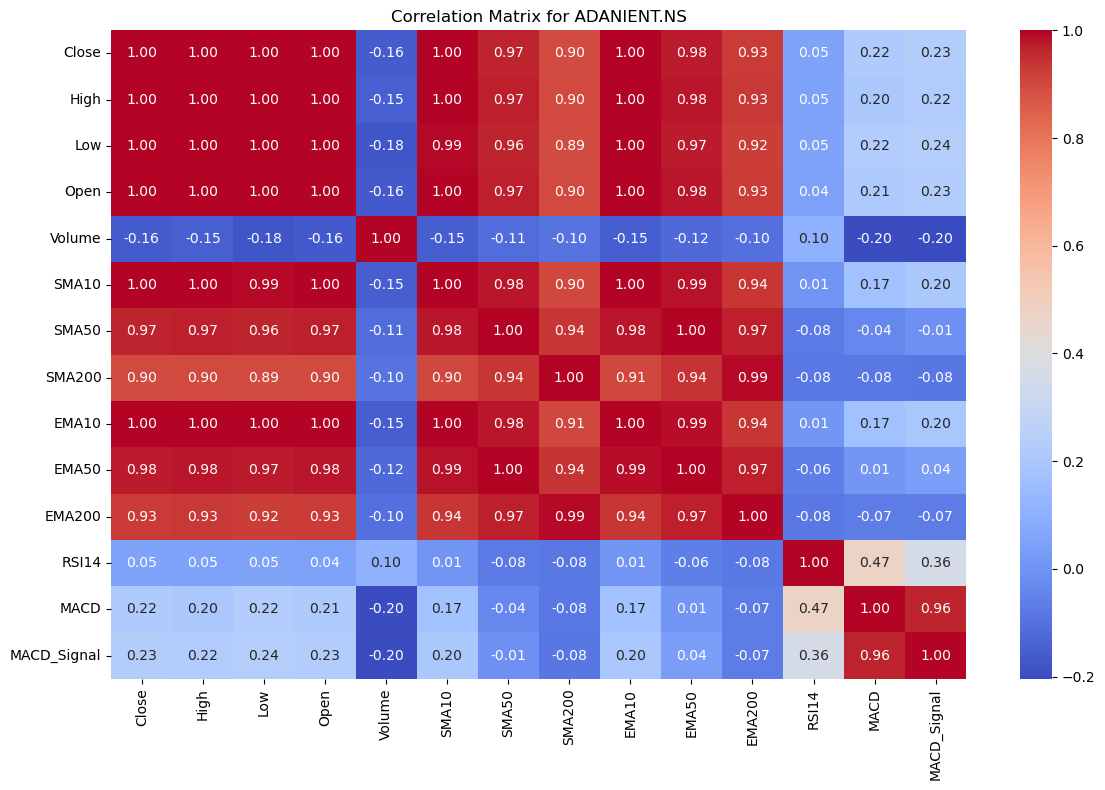

Top features correlated with 'Close' for ADANIENT.NS:
Low            0.999471
High           0.999229
Open           0.998733
EMA10          0.996627
SMA10          0.995408
EMA50          0.976117
SMA50          0.966244
EMA200         0.926938
SMA200         0.896203
MACD_Signal    0.229153
MACD           0.215731
RSI14          0.052299
Volume        -0.159946
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ADANIENT.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



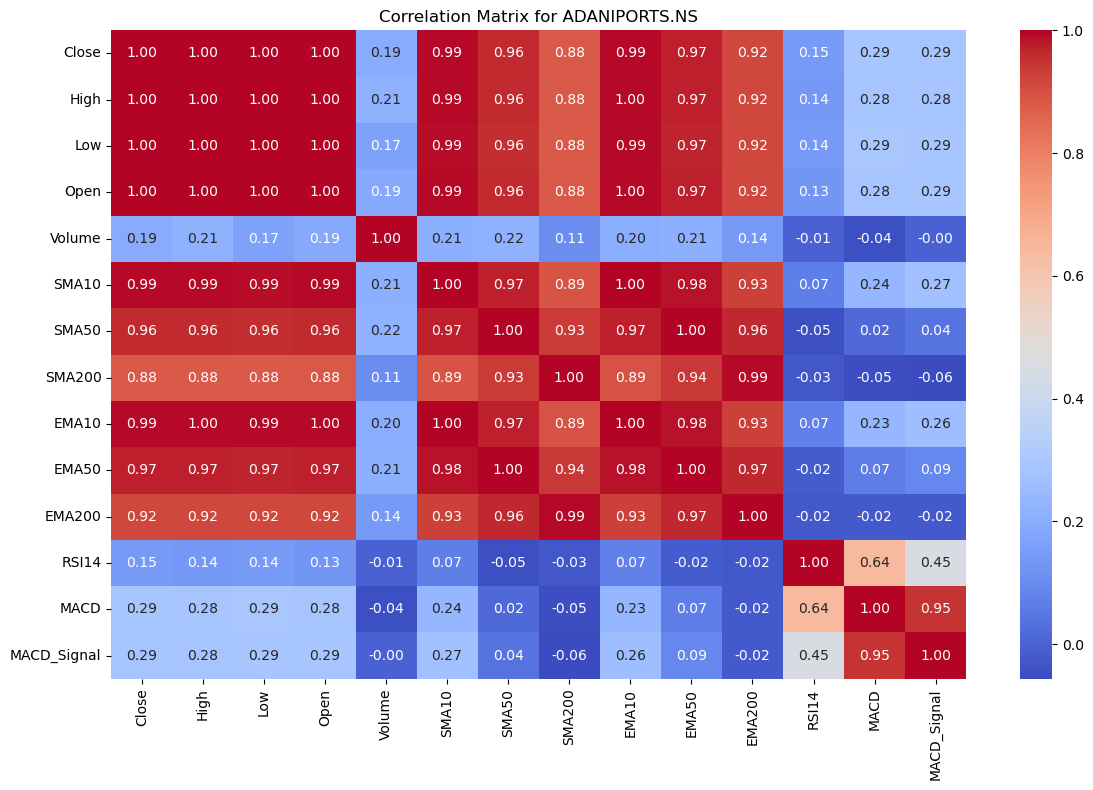

Top features correlated with 'Close' for ADANIPORTS.NS:
High           0.998943
Low            0.998867
Open           0.997754
EMA10          0.994345
SMA10          0.991749
EMA50          0.971276
SMA50          0.959323
EMA200         0.915779
SMA200         0.880032
MACD           0.286782
MACD_Signal    0.285948
Volume         0.192379
RSI14          0.145340
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ADANIPORTS.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



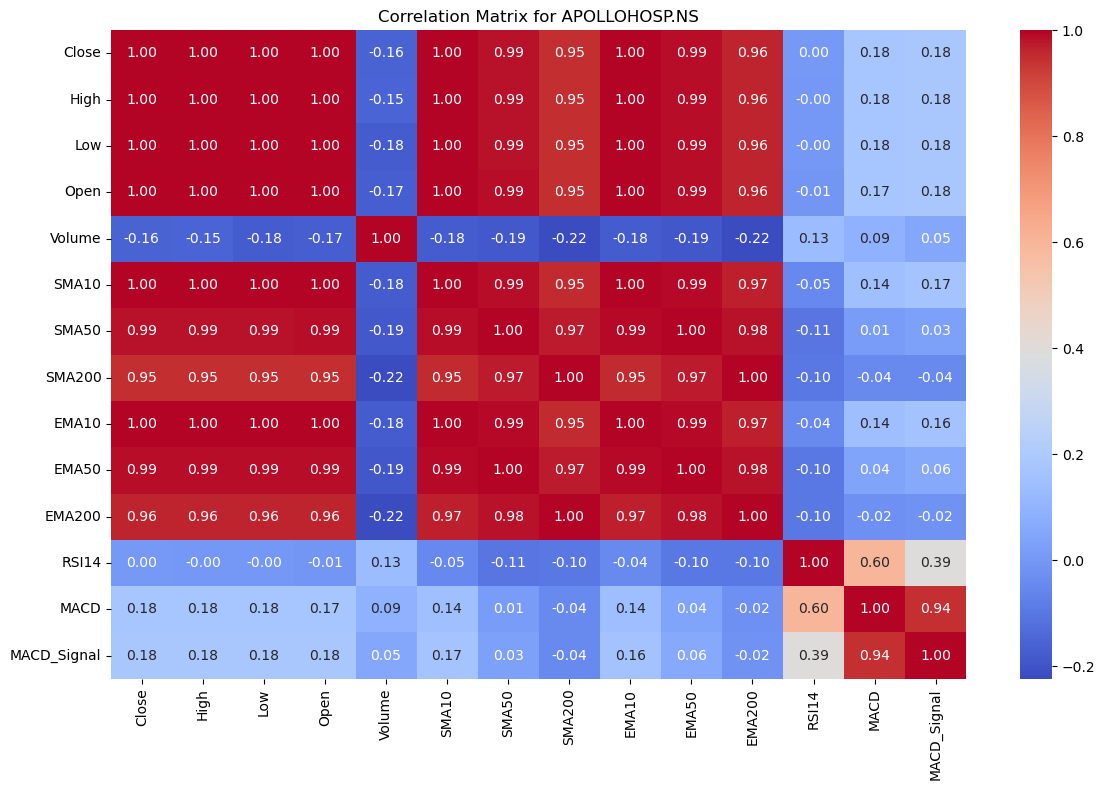

Top features correlated with 'Close' for APOLLOHOSP.NS:
High           0.999631
Low            0.999517
Open           0.999004
EMA10          0.997885
SMA10          0.997106
EMA50          0.989419
SMA50          0.985339
EMA200         0.963793
SMA200         0.949300
MACD_Signal    0.179150
MACD           0.175585
RSI14          0.003217
Volume        -0.160848
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for APOLLOHOSP.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



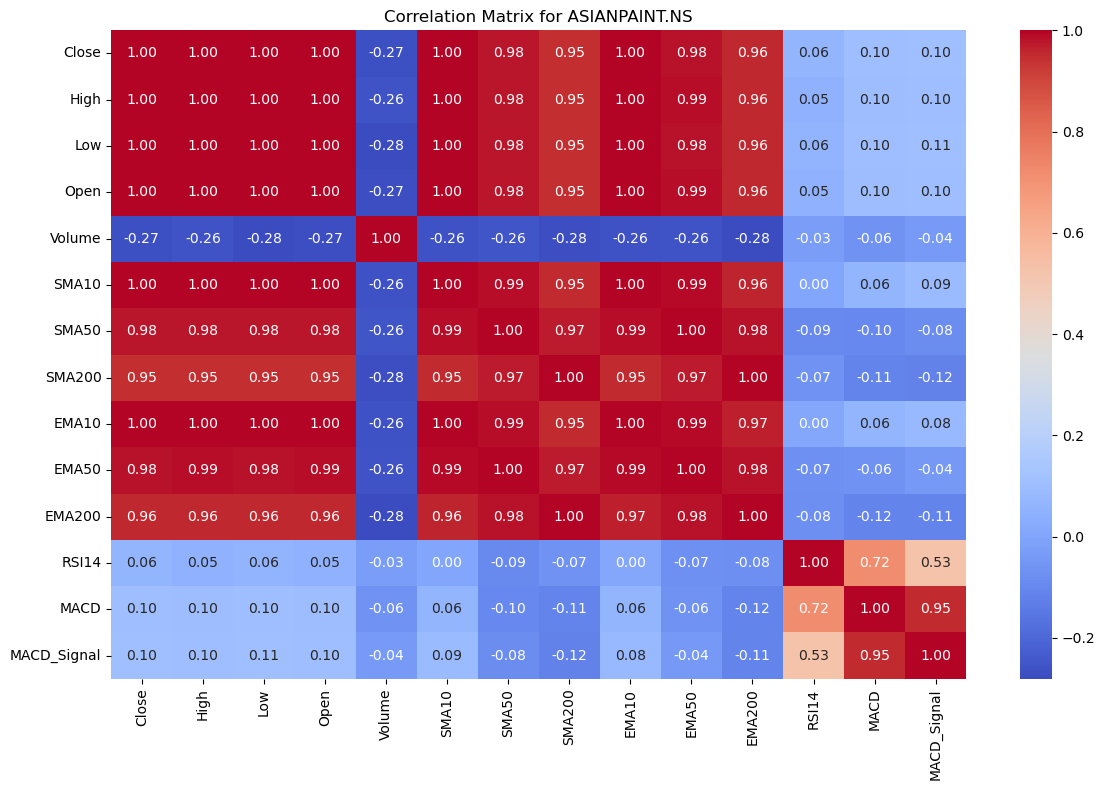

Top features correlated with 'Close' for ASIANPAINT.NS:
High           0.999505
Low            0.999456
Open           0.998762
EMA10          0.997100
SMA10          0.995915
EMA50          0.984899
SMA50          0.978138
EMA200         0.958385
SMA200         0.948130
MACD_Signal    0.104979
MACD           0.101583
RSI14          0.060776
Volume        -0.267334
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ASIANPAINT.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



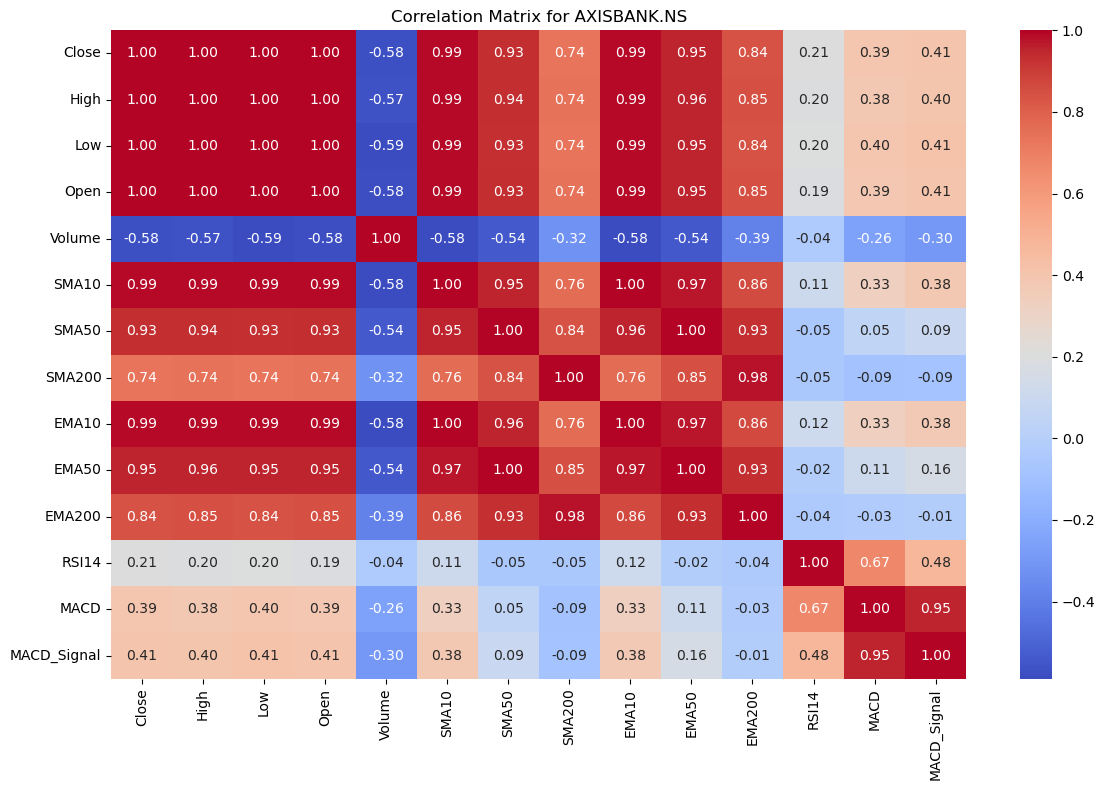

Top features correlated with 'Close' for AXISBANK.NS:
High           0.998807
Low            0.998656
Open           0.997187
EMA10          0.991766
SMA10          0.988347
EMA50          0.951528
SMA50          0.931841
EMA200         0.842327
SMA200         0.738932
MACD_Signal    0.410066
MACD           0.393669
RSI14          0.207665
Volume        -0.575741
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for AXISBANK.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



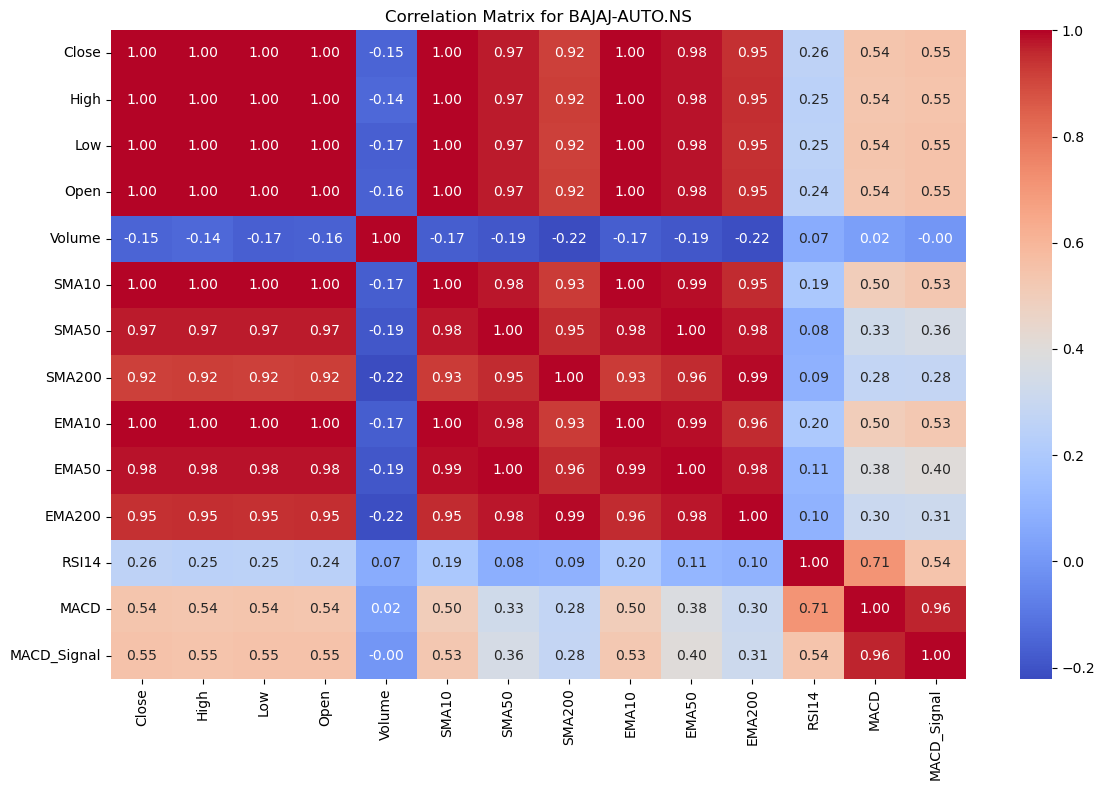

Top features correlated with 'Close' for BAJAJ-AUTO.NS:
High           0.999351
Low            0.999278
Open           0.998476
EMA10          0.996698
SMA10          0.995406
EMA50          0.981071
SMA50          0.971420
EMA200         0.946900
SMA200         0.918543
MACD_Signal    0.547967
MACD           0.538639
RSI14          0.256346
Volume        -0.149840
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for BAJAJ-AUTO.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



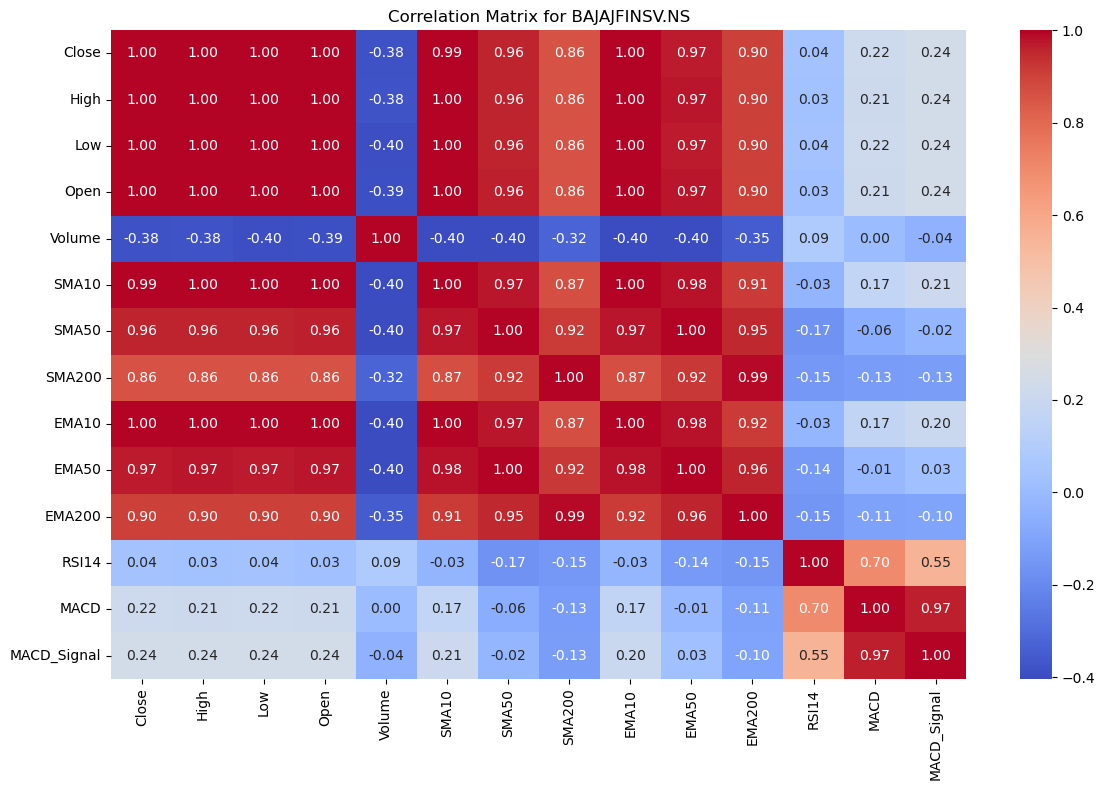

Top features correlated with 'Close' for BAJAJFINSV.NS:
High           0.999436
Low            0.999401
Open           0.998598
EMA10          0.996256
SMA10          0.994983
EMA50          0.971407
SMA50          0.959551
EMA200         0.903029
SMA200         0.860385
MACD_Signal    0.241281
MACD           0.217334
RSI14          0.040524
Volume        -0.383438
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for BAJAJFINSV.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



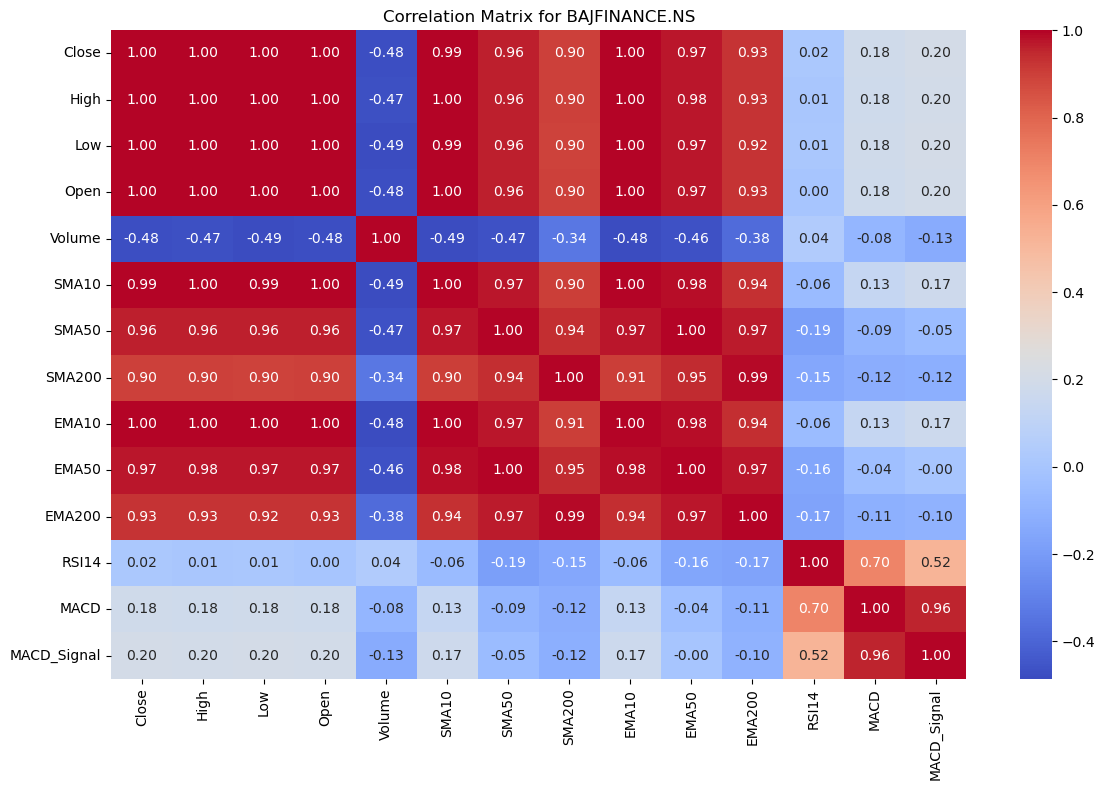

Top features correlated with 'Close' for BAJFINANCE.NS:
High           0.999395
Low            0.999314
Open           0.998432
EMA10          0.995743
SMA10          0.994238
EMA50          0.973302
SMA50          0.961106
EMA200         0.925455
SMA200         0.895832
MACD_Signal    0.200254
MACD           0.181718
RSI14          0.015916
Volume        -0.475903
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for BAJFINANCE.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



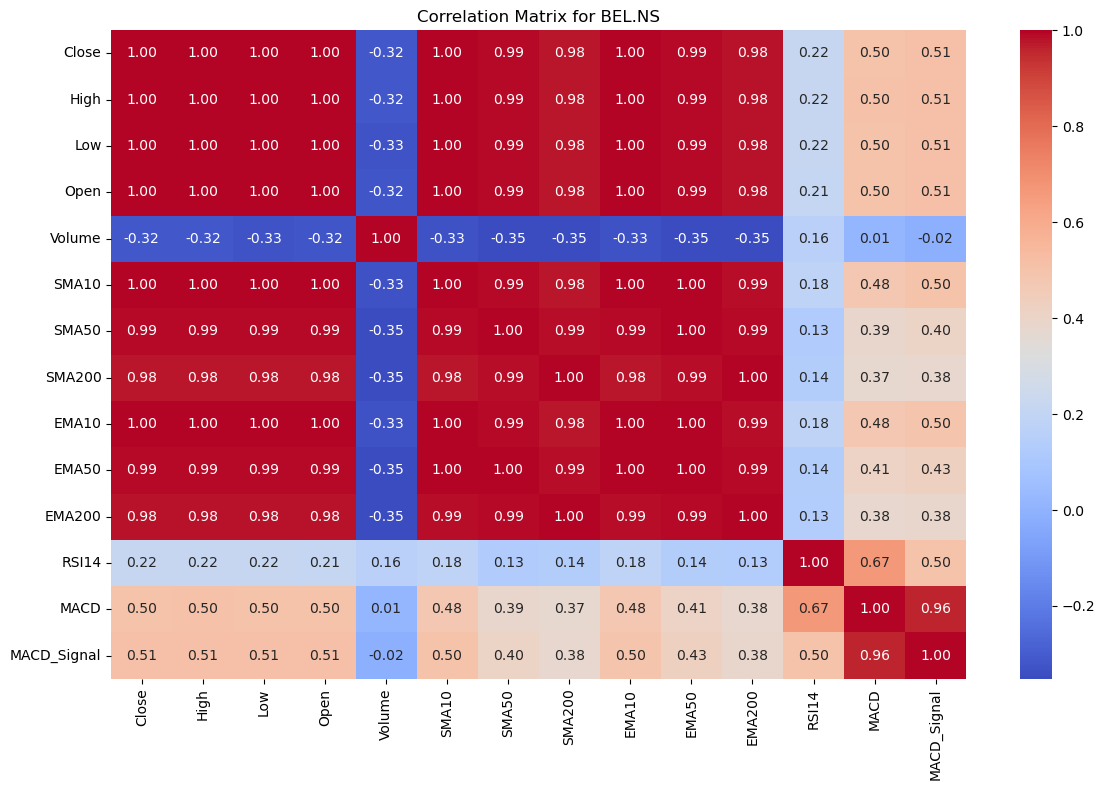

Top features correlated with 'Close' for BEL.NS:
Low            0.999760
High           0.999752
Open           0.999377
EMA10          0.998748
SMA10          0.998245
EMA50          0.993588
SMA50          0.990877
EMA200         0.982601
SMA200         0.975672
MACD_Signal    0.510161
MACD           0.503088
RSI14          0.218437
Volume        -0.319678
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for BEL.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



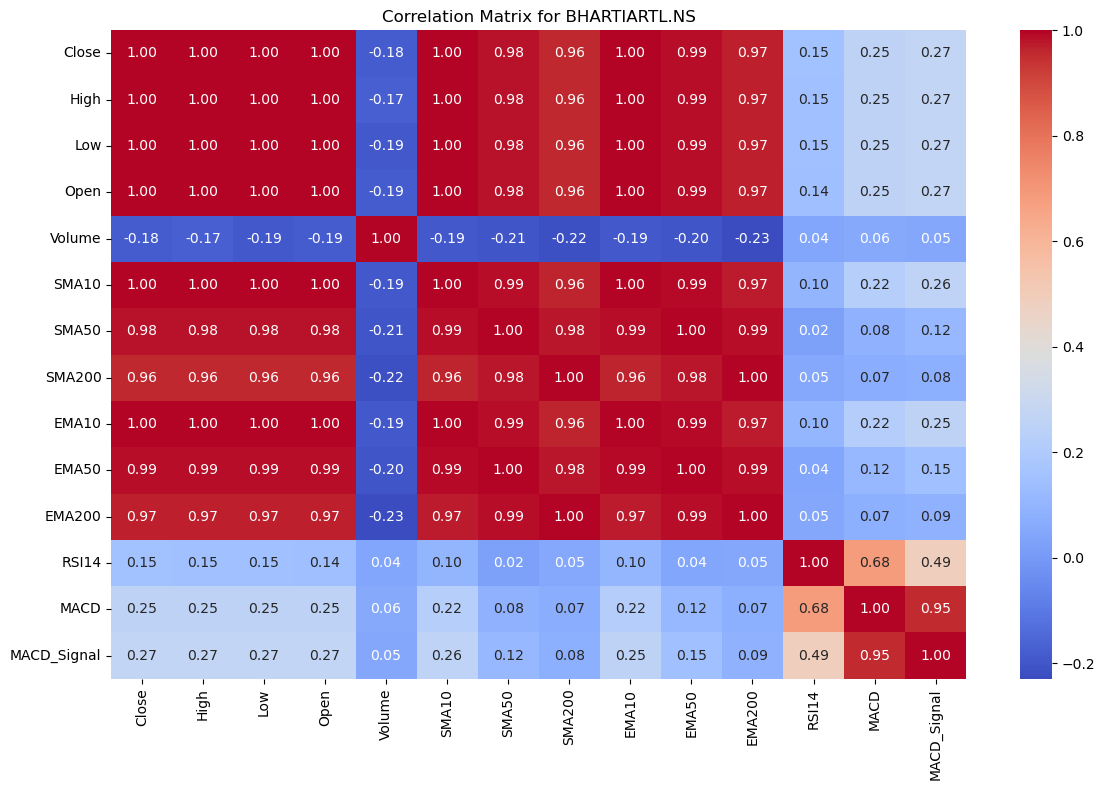

Top features correlated with 'Close' for BHARTIARTL.NS:
High           0.999541
Low            0.999351
Open           0.998786
EMA10          0.997852
SMA10          0.997007
EMA50          0.988783
SMA50          0.983922
EMA200         0.970371
SMA200         0.960281
MACD_Signal    0.273002
MACD           0.253612
RSI14          0.152057
Volume        -0.183518
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for BHARTIARTL.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



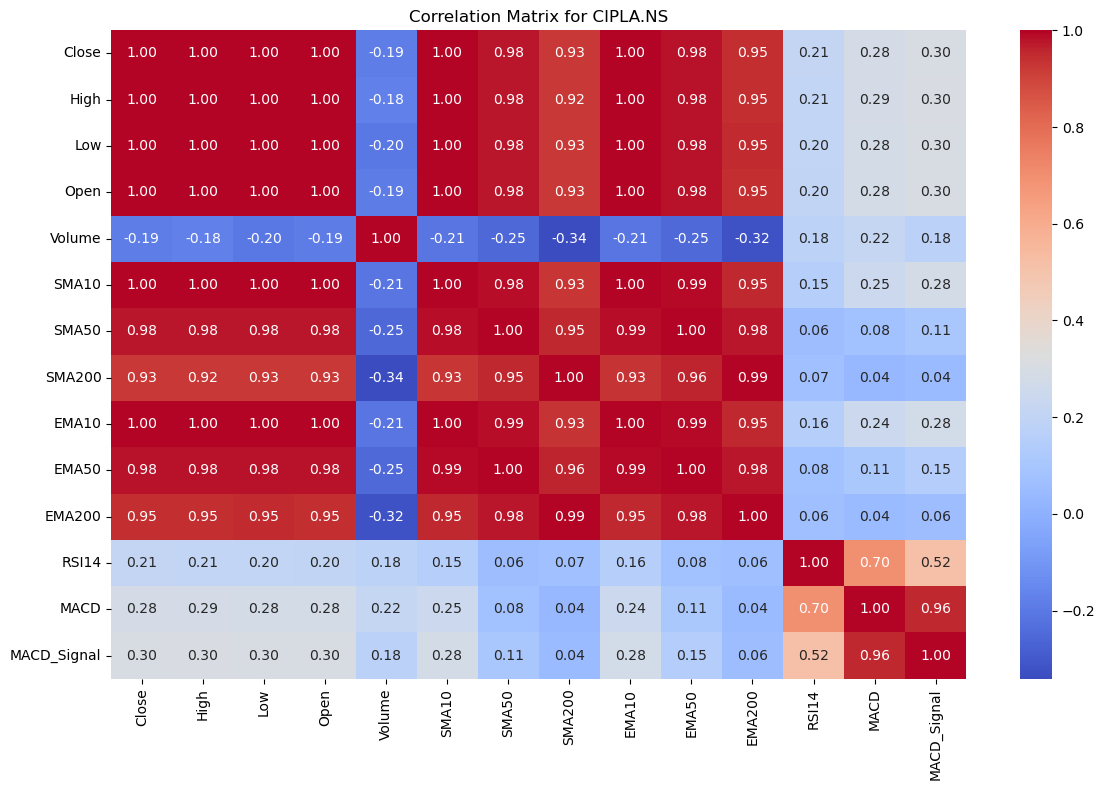

Top features correlated with 'Close' for CIPLA.NS:
Low            0.999420
High           0.999413
Open           0.998652
EMA10          0.997178
SMA10          0.996087
EMA50          0.983137
SMA50          0.976549
EMA200         0.946965
SMA200         0.925825
MACD_Signal    0.300232
MACD           0.282751
RSI14          0.210175
Volume        -0.186837
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for CIPLA.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



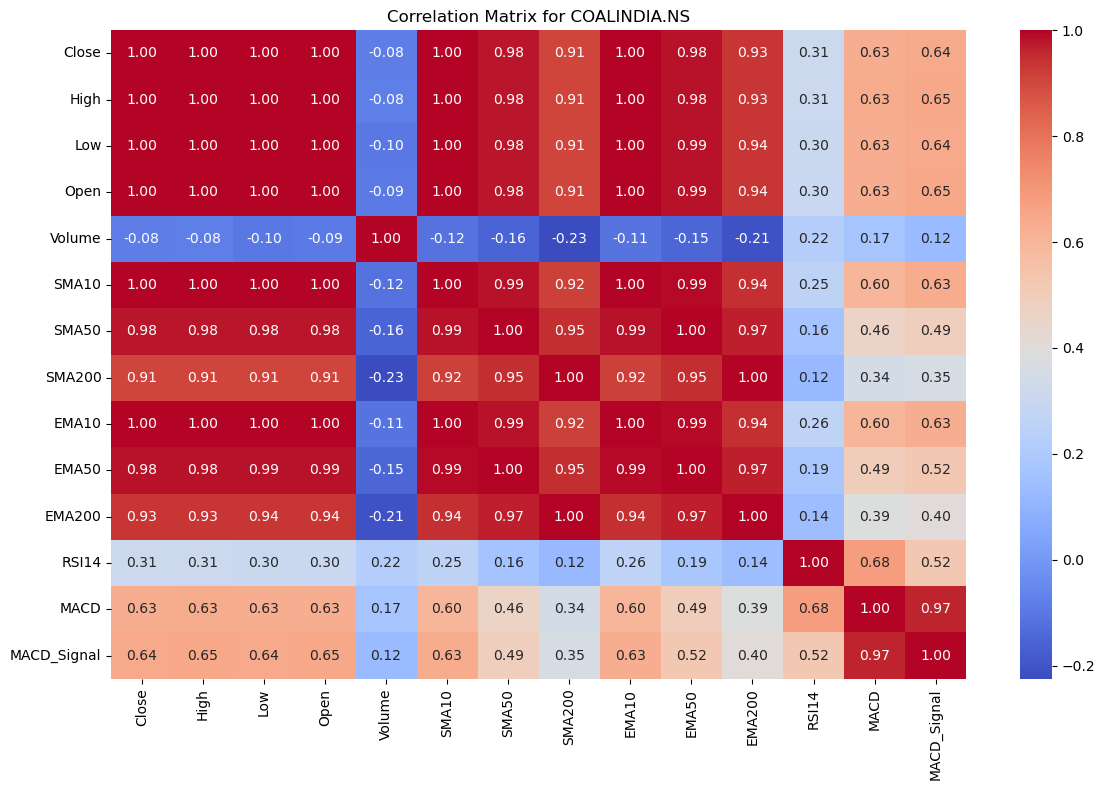

Top features correlated with 'Close' for COALINDIA.NS:
High           0.999575
Low            0.999435
Open           0.998782
EMA10          0.997362
SMA10          0.996198
EMA50          0.984537
SMA50          0.977790
EMA200         0.934973
SMA200         0.906839
MACD_Signal    0.644690
MACD           0.630194
RSI14          0.308583
Volume        -0.084833
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for COALINDIA.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



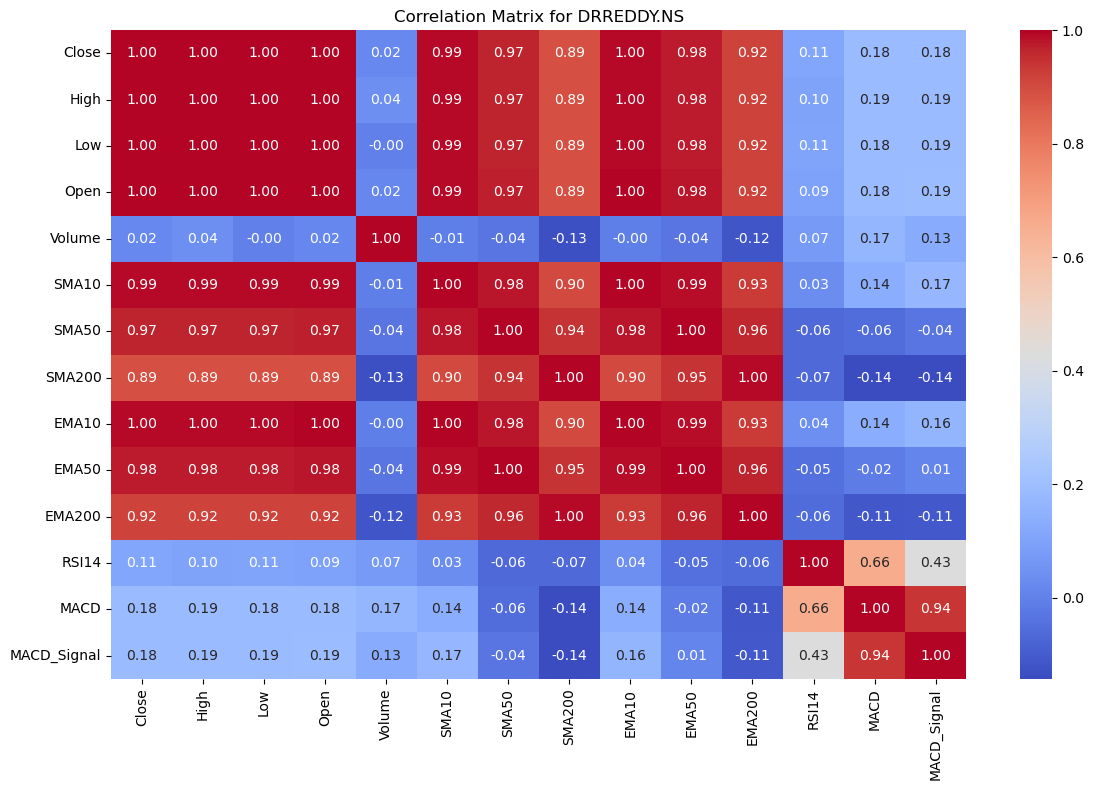

Top features correlated with 'Close' for DRREDDY.NS:
High           0.999005
Low            0.998954
Open           0.997937
EMA10          0.995083
SMA10          0.993032
EMA50          0.976535
SMA50          0.967937
EMA200         0.918458
SMA200         0.892127
MACD           0.184103
MACD_Signal    0.184004
RSI14          0.110103
Volume         0.020146
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for DRREDDY.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



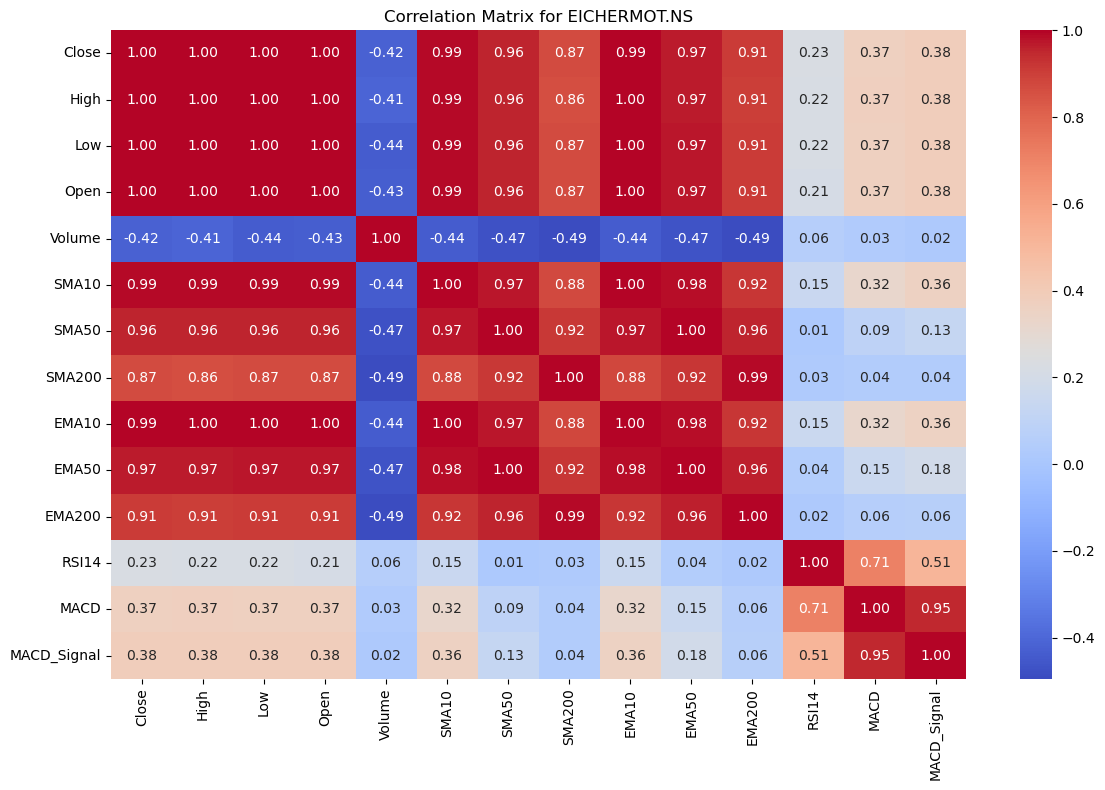

Top features correlated with 'Close' for EICHERMOT.NS:
Low            0.998994
High           0.998934
Open           0.997478
EMA10          0.994577
SMA10          0.992106
EMA50          0.970148
SMA50          0.956804
EMA200         0.907563
SMA200         0.866967
MACD_Signal    0.381886
MACD           0.368764
RSI14          0.227255
Volume        -0.422469
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for EICHERMOT.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



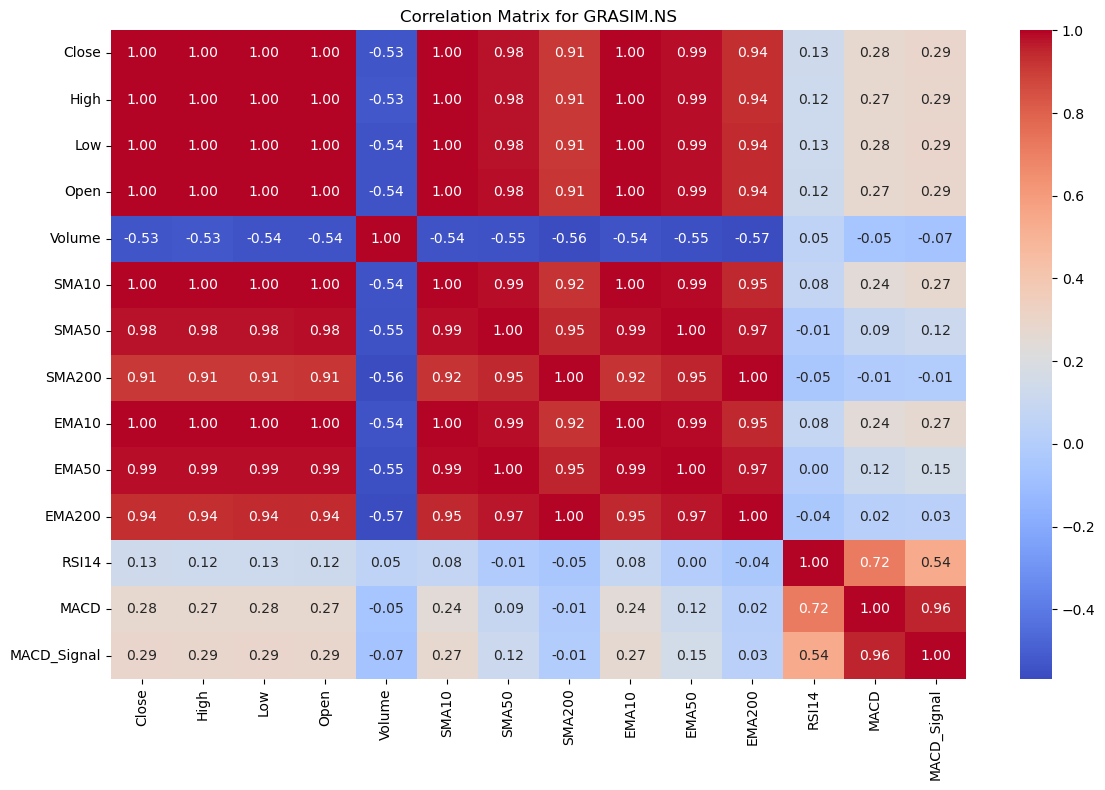

Top features correlated with 'Close' for GRASIM.NS:
Low            0.999616
High           0.999598
Open           0.999043
EMA10          0.997758
SMA10          0.996812
EMA50          0.986103
SMA50          0.980771
EMA200         0.938390
SMA200         0.913866
MACD_Signal    0.290001
MACD           0.276281
RSI14          0.131021
Volume        -0.534899
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for GRASIM.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



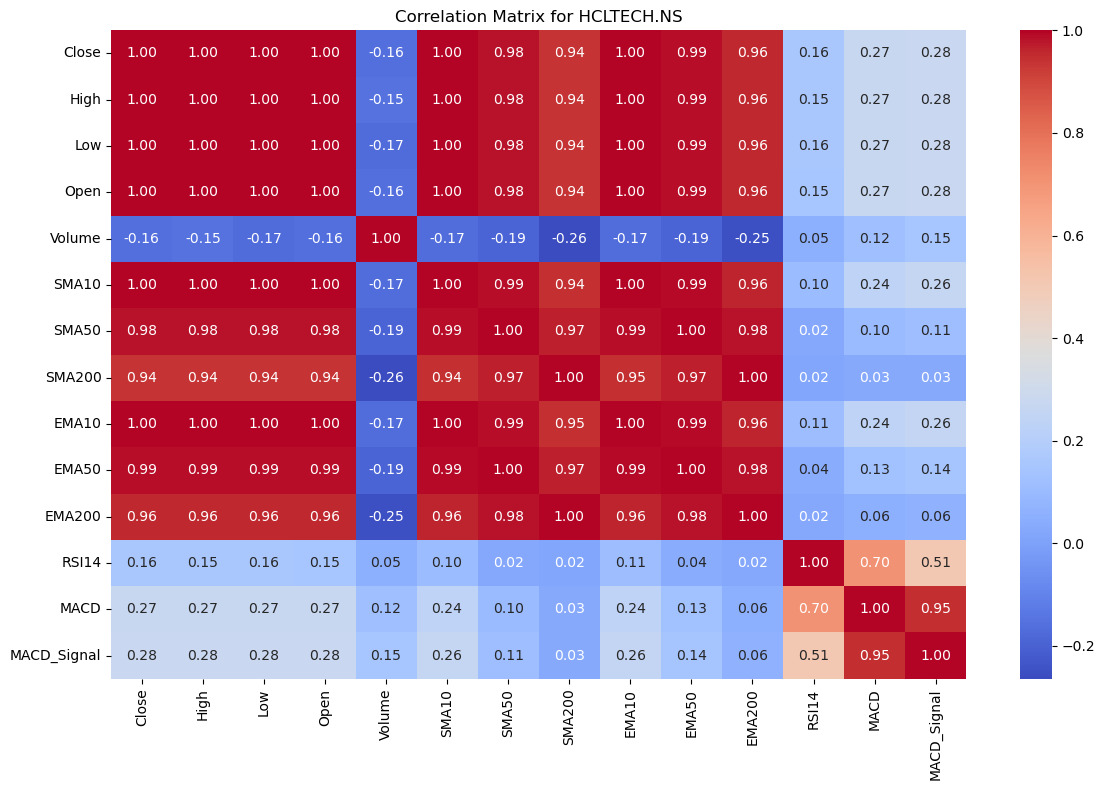

Top features correlated with 'Close' for HCLTECH.NS:
High           0.999590
Low            0.999587
Open           0.999031
EMA10          0.997622
SMA10          0.996648
EMA50          0.987294
SMA50          0.982544
EMA200         0.957667
SMA200         0.938502
MACD_Signal    0.275303
MACD           0.273247
RSI14          0.158600
Volume        -0.163889
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HCLTECH.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



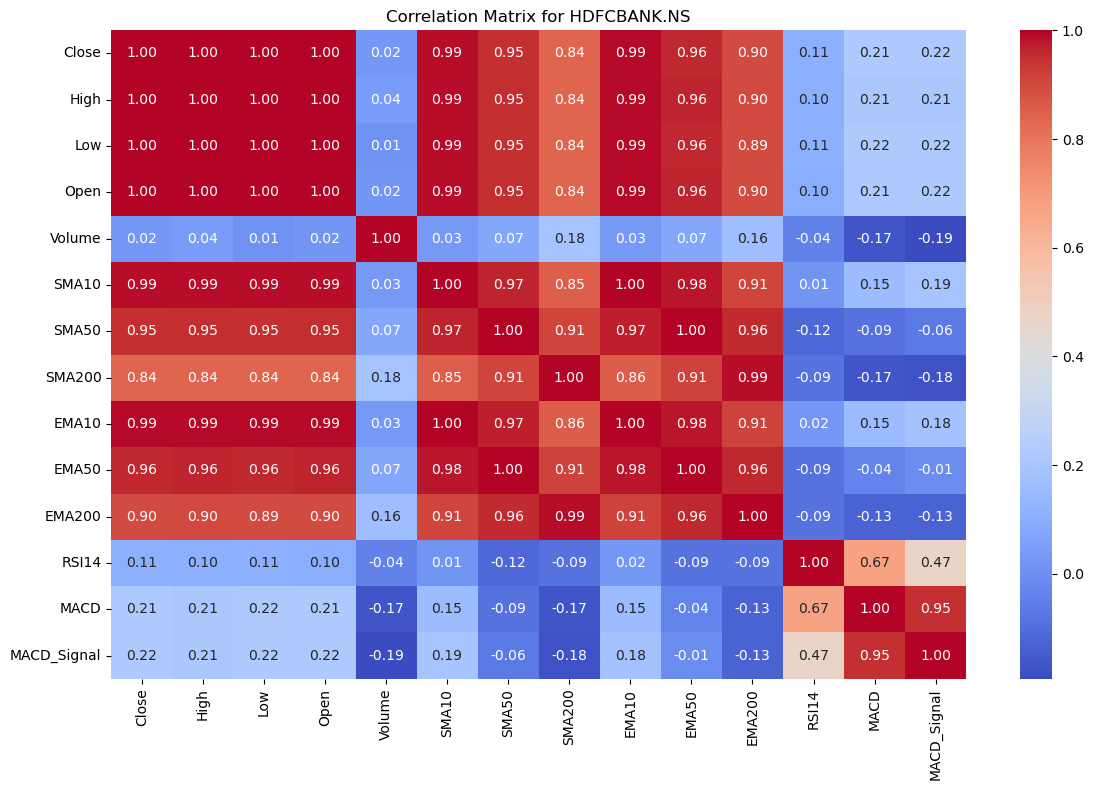

Top features correlated with 'Close' for HDFCBANK.NS:
High           0.998797
Low            0.998595
Open           0.997116
EMA10          0.992387
SMA10          0.988930
EMA50          0.962477
SMA50          0.948688
EMA200         0.895597
SMA200         0.839307
MACD_Signal    0.215406
MACD           0.214431
RSI14          0.108453
Volume         0.021574
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HDFCBANK.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



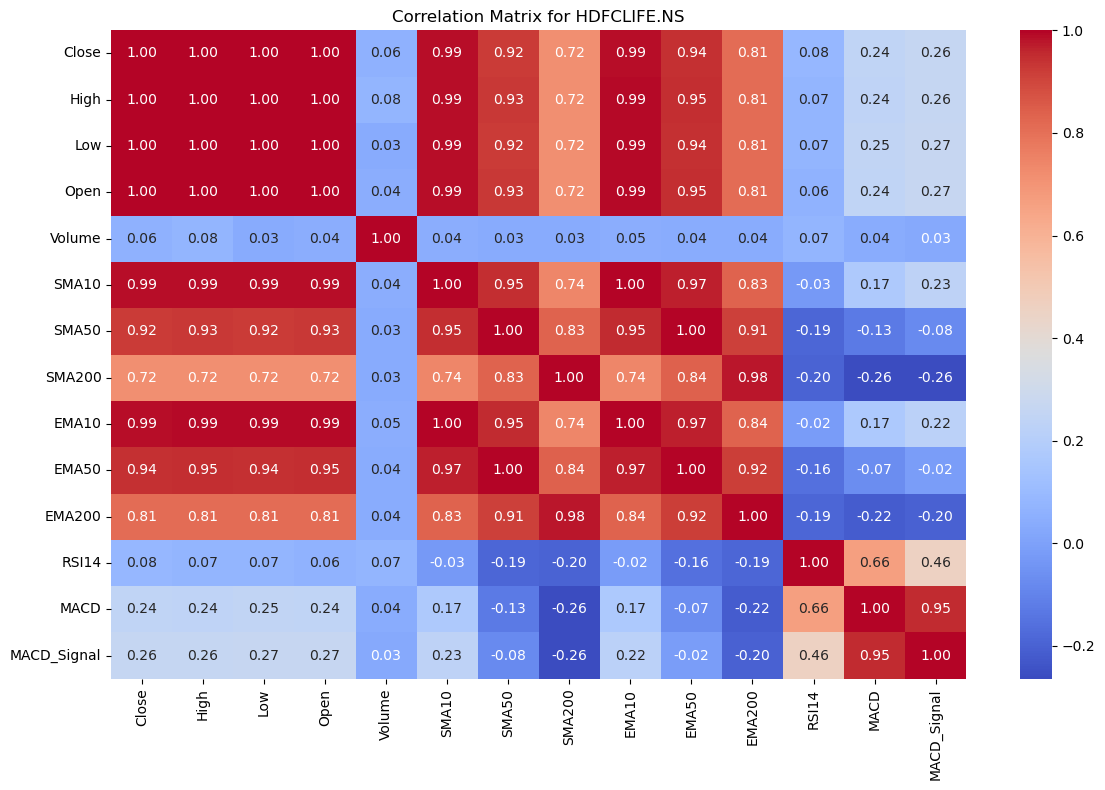

Top features correlated with 'Close' for HDFCLIFE.NS:
High           0.997913
Low            0.997747
Open           0.995123
EMA10          0.989926
SMA10          0.985985
EMA50          0.944315
SMA50          0.924345
EMA200         0.809217
SMA200         0.715624
MACD_Signal    0.264061
MACD           0.242522
RSI14          0.082699
Volume         0.060103
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HDFCLIFE.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



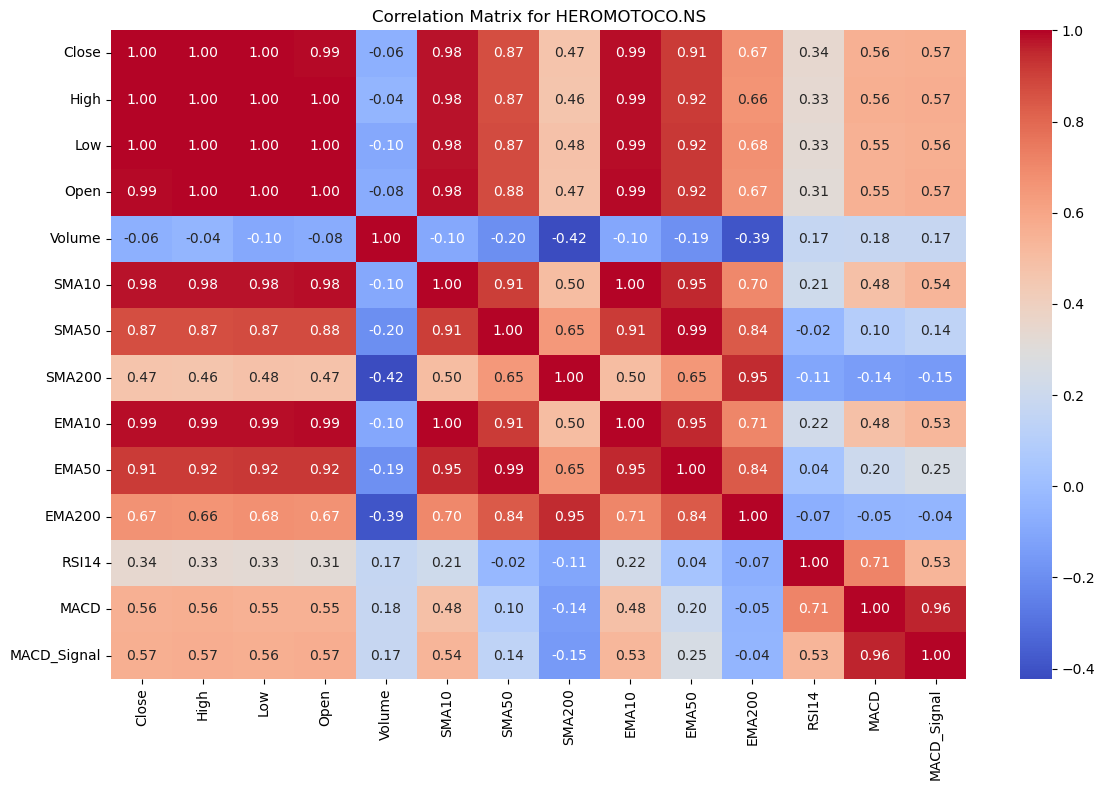

Top features correlated with 'Close' for HEROMOTOCO.NS:
High           0.997080
Low            0.996793
Open           0.992762
EMA10          0.985099
SMA10          0.978635
EMA50          0.914778
SMA50          0.870345
EMA200         0.667585
MACD_Signal    0.566002
MACD           0.559032
SMA200         0.470242
RSI14          0.342764
Volume        -0.063636
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HEROMOTOCO.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



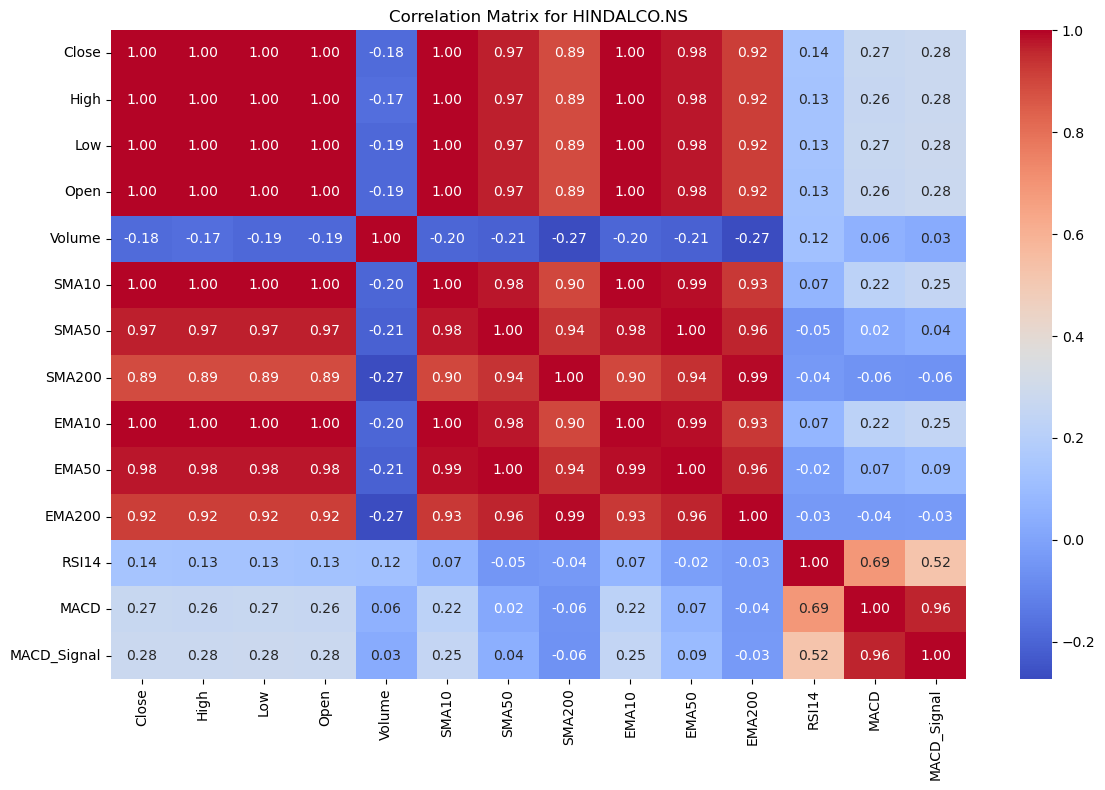

Top features correlated with 'Close' for HINDALCO.NS:
High           0.999522
Low            0.999478
Open           0.998669
EMA10          0.996402
SMA10          0.995119
EMA50          0.976852
SMA50          0.966123
EMA200         0.917057
SMA200         0.888592
MACD_Signal    0.278937
MACD           0.267358
RSI14          0.137727
Volume        -0.178661
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HINDALCO.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



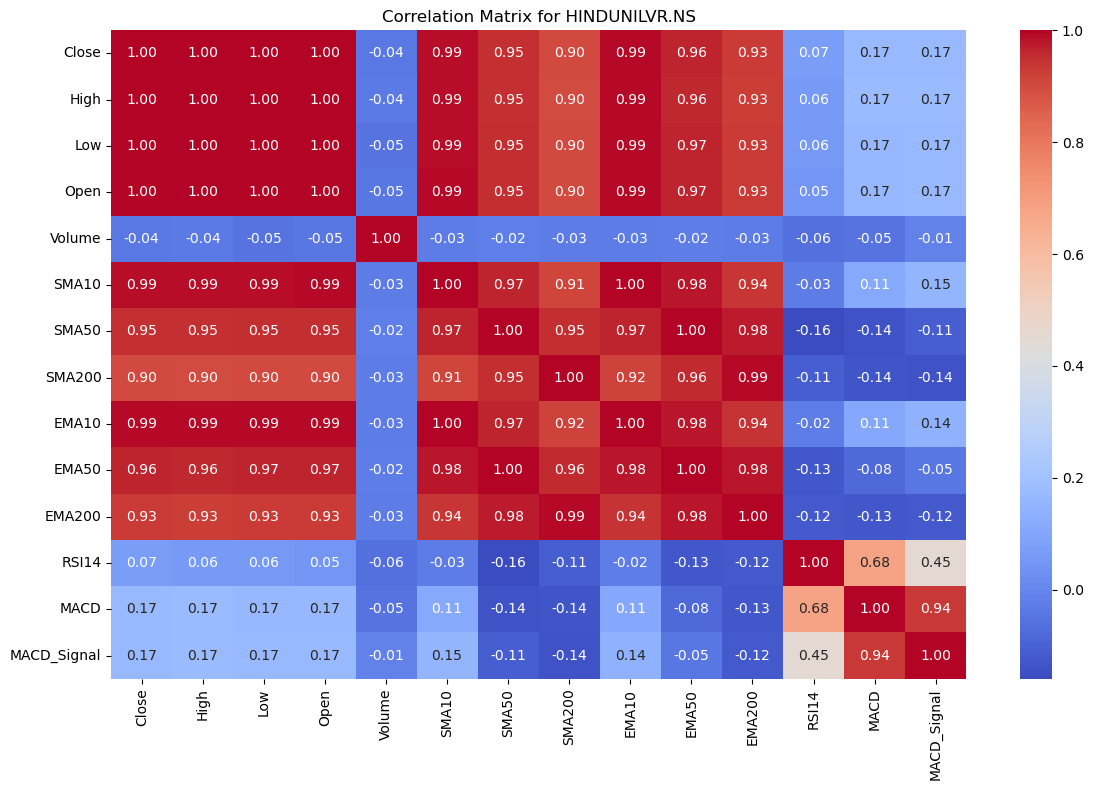

Top features correlated with 'Close' for HINDUNILVR.NS:
High           0.998329
Low            0.998237
Open           0.996079
EMA10          0.991824
SMA10          0.988549
EMA50          0.964003
SMA50          0.948267
EMA200         0.928836
SMA200         0.902145
MACD           0.169823
MACD_Signal    0.168200
RSI14          0.068698
Volume        -0.040779
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for HINDUNILVR.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



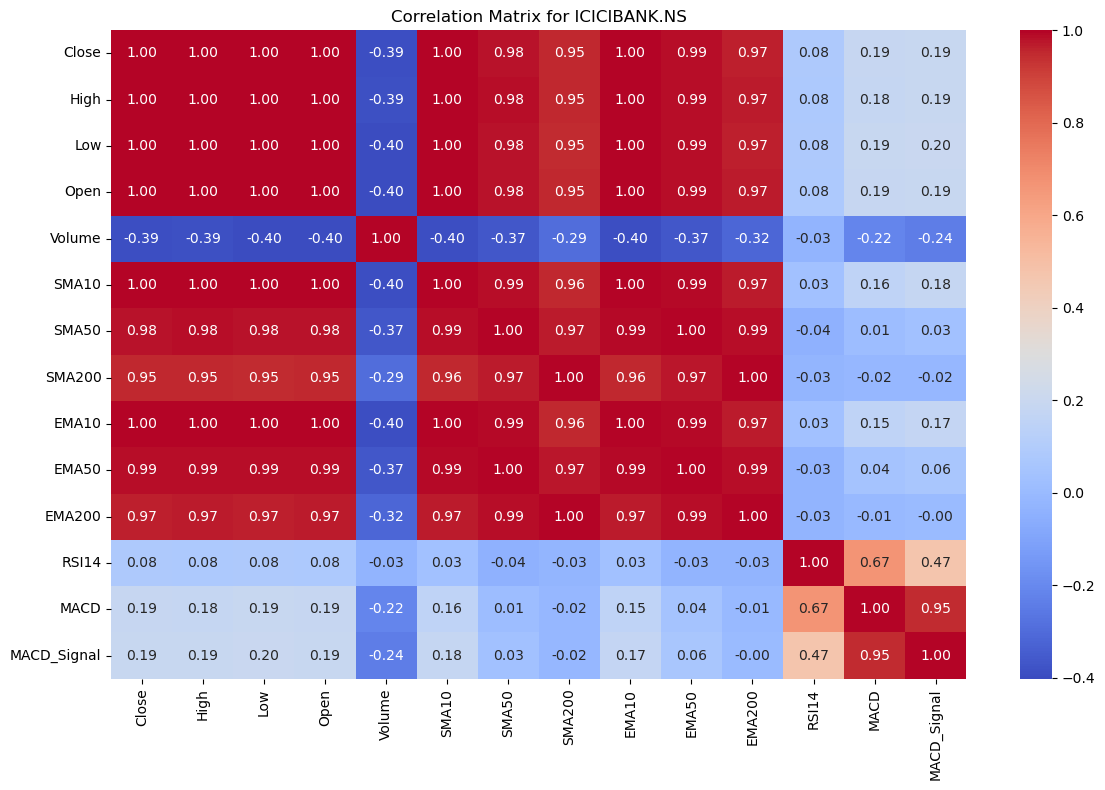

Top features correlated with 'Close' for ICICIBANK.NS:
High           0.999694
Low            0.999664
Open           0.999217
EMA10          0.997709
SMA10          0.996773
EMA50          0.987612
SMA50          0.982891
EMA200         0.966764
SMA200         0.950952
MACD_Signal    0.194095
MACD           0.188818
RSI14          0.083551
Volume        -0.394916
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ICICIBANK.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



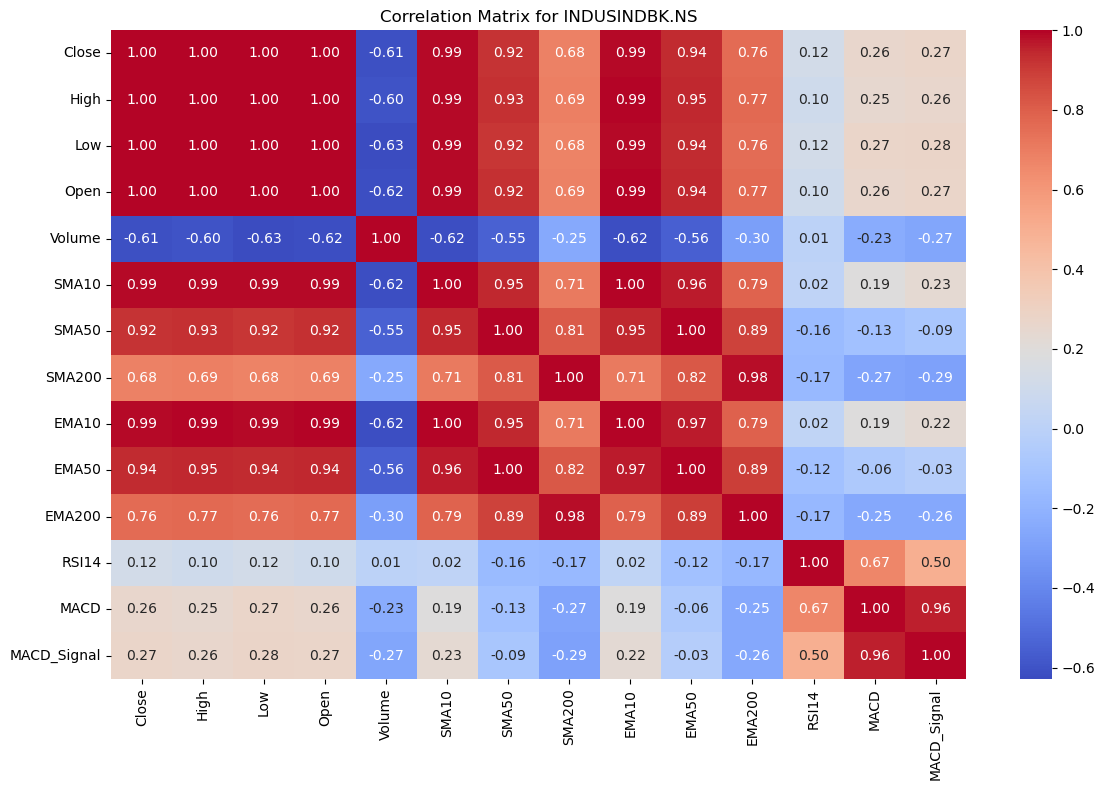

Top features correlated with 'Close' for INDUSINDBK.NS:
High           0.998721
Low            0.998550
Open           0.997028
EMA10          0.991657
SMA10          0.988403
EMA50          0.941219
SMA50          0.920475
EMA200         0.762519
SMA200         0.683808
MACD_Signal    0.270921
MACD           0.261292
RSI14          0.117455
Volume        -0.613969
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for INDUSINDBK.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



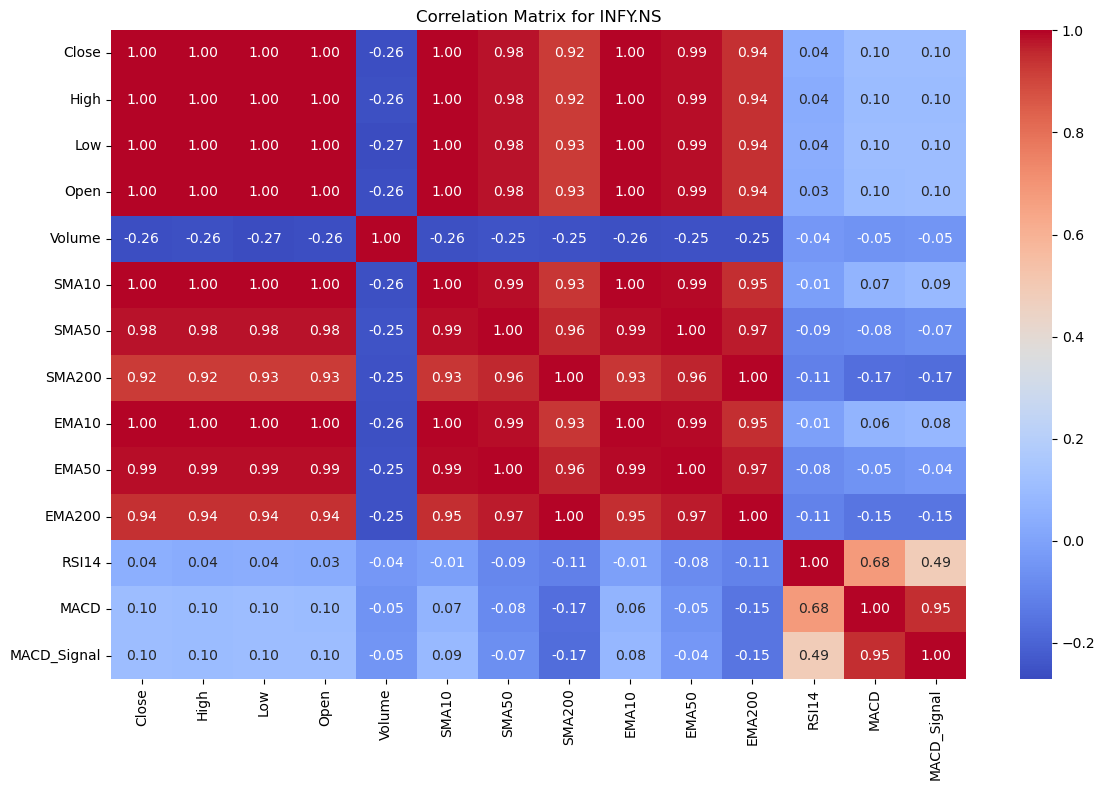

Top features correlated with 'Close' for INFY.NS:
Low            0.999715
High           0.999711
Open           0.999268
EMA10          0.997472
SMA10          0.996409
EMA50          0.986187
SMA50          0.981543
EMA200         0.942430
SMA200         0.924958
MACD_Signal    0.103355
MACD           0.102076
RSI14          0.042460
Volume        -0.262846
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for INFY.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



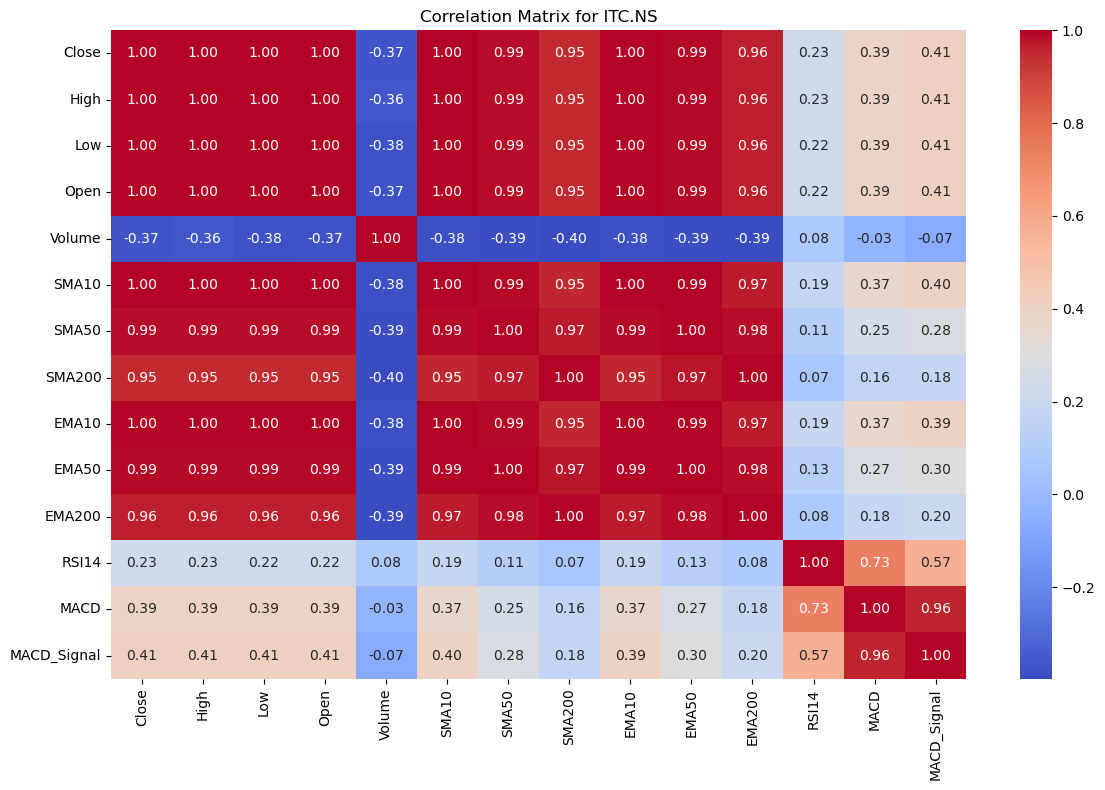

Top features correlated with 'Close' for ITC.NS:
High           0.999728
Low            0.999659
Open           0.999315
EMA10          0.998518
SMA10          0.997884
EMA50          0.991014
SMA50          0.987670
EMA200         0.962666
SMA200         0.948158
MACD_Signal    0.410850
MACD           0.391921
RSI14          0.227691
Volume        -0.368402
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ITC.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']

JIOFIN.NS: DataFrame is empty, skipping.


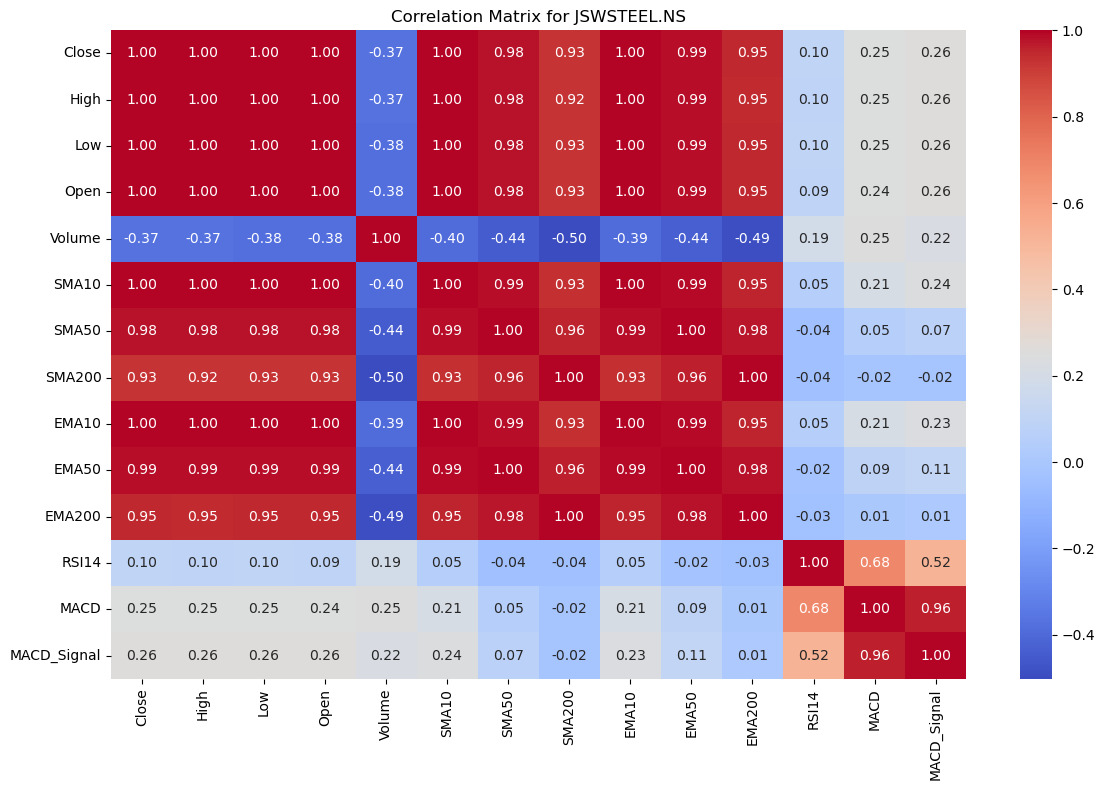

Top features correlated with 'Close' for JSWSTEEL.NS:
High           0.999671
Low            0.999652
Open           0.999132
EMA10          0.997840
SMA10          0.997065
EMA50          0.985820
SMA50          0.979357
EMA200         0.947263
SMA200         0.925181
MACD_Signal    0.258301
MACD           0.246981
RSI14          0.100836
Volume        -0.372875
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for JSWSTEEL.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



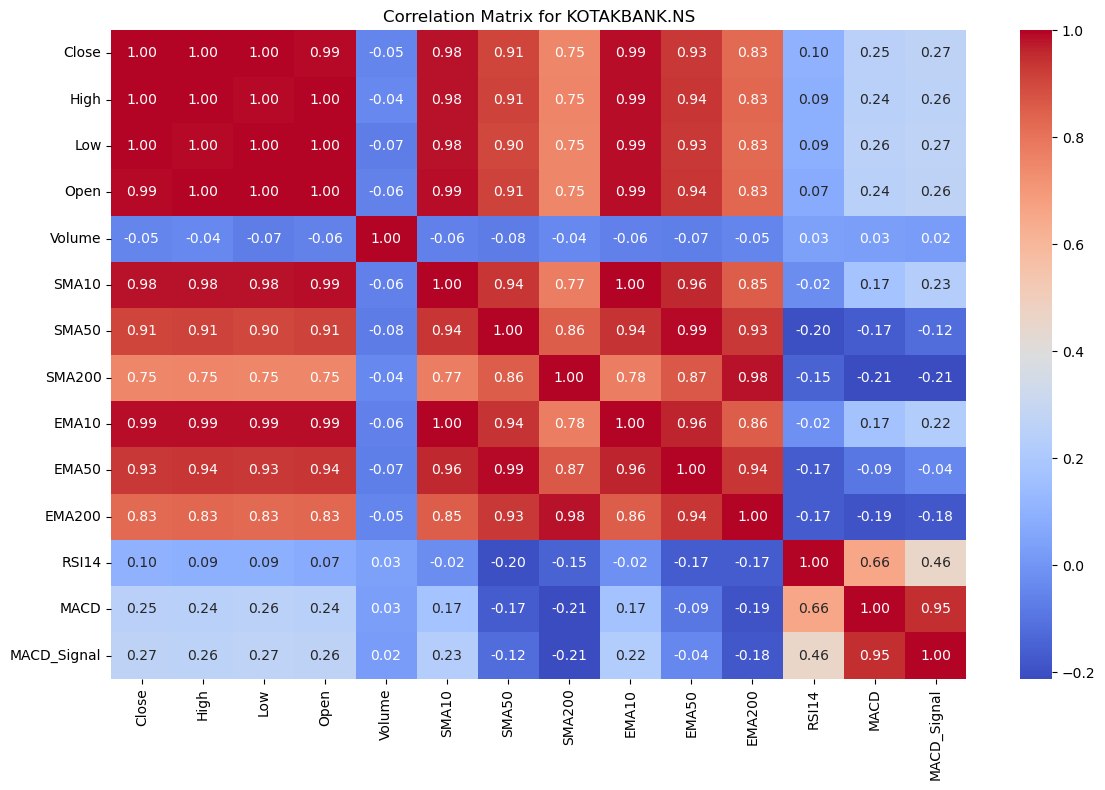

Top features correlated with 'Close' for KOTAKBANK.NS:
High           0.997715
Low            0.996624
Open           0.994455
EMA10          0.987454
SMA10          0.982224
EMA50          0.932719
SMA50          0.905945
EMA200         0.829129
SMA200         0.752036
MACD_Signal    0.265102
MACD           0.250627
RSI14          0.096978
Volume        -0.051480
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for KOTAKBANK.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



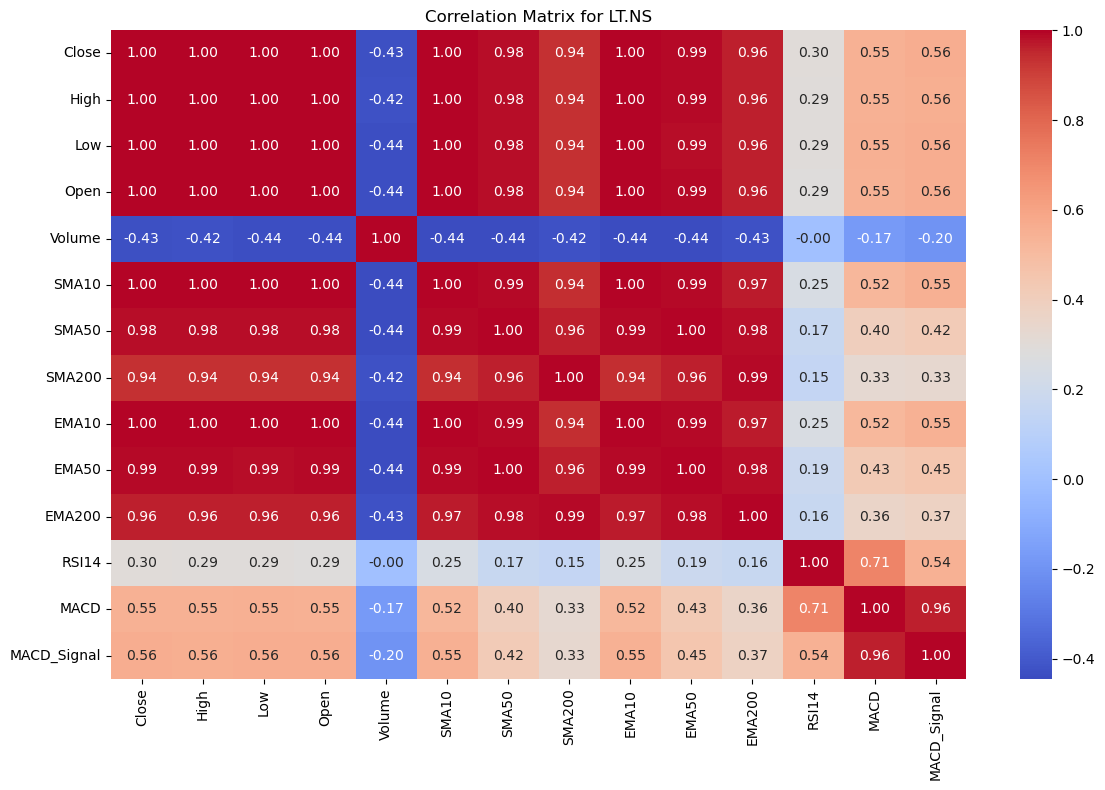

Top features correlated with 'Close' for LT.NS:
High           0.999725
Low            0.999661
Open           0.999276
EMA10          0.997995
SMA10          0.997102
EMA50          0.988739
SMA50          0.984039
EMA200         0.962531
SMA200         0.935741
MACD_Signal    0.559964
MACD           0.547638
RSI14          0.295957
Volume        -0.429336
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for LT.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



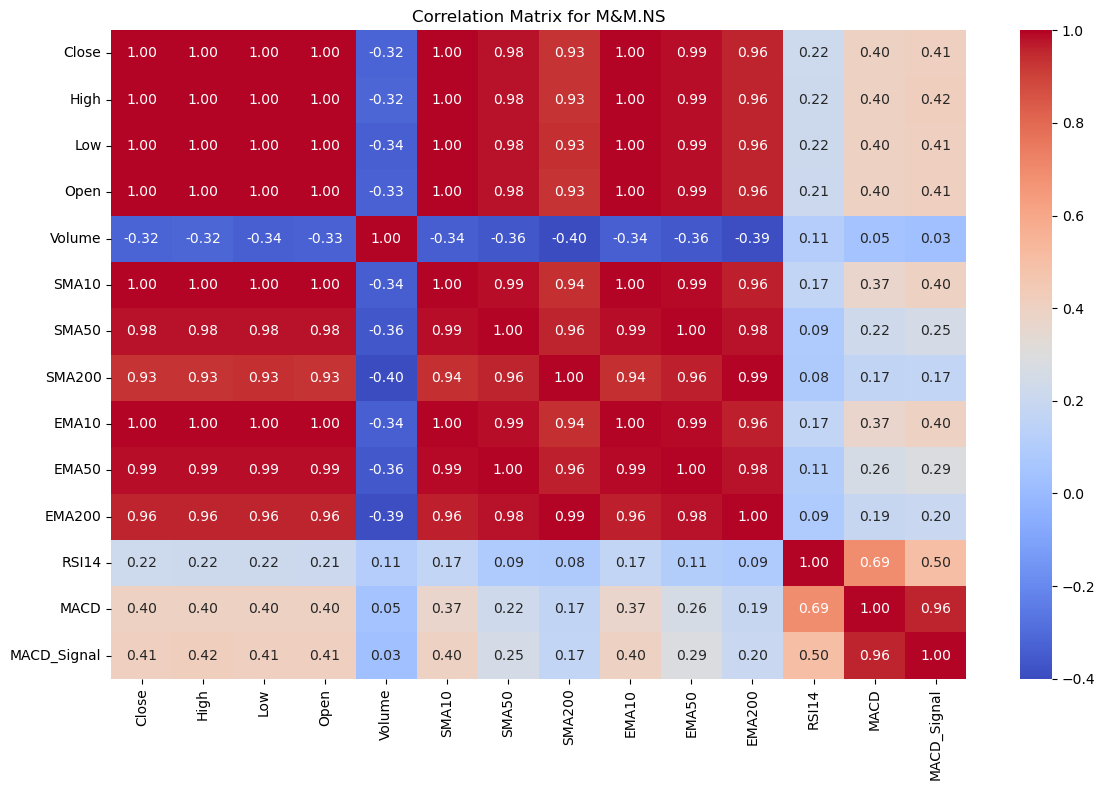

Top features correlated with 'Close' for M&M.NS:
High           0.999643
Low            0.999611
Open           0.999061
EMA10          0.997804
SMA10          0.996835
EMA50          0.987243
SMA50          0.981619
EMA200         0.957097
SMA200         0.933783
MACD_Signal    0.413475
MACD           0.399365
RSI14          0.220783
Volume        -0.322853
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for M&M.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



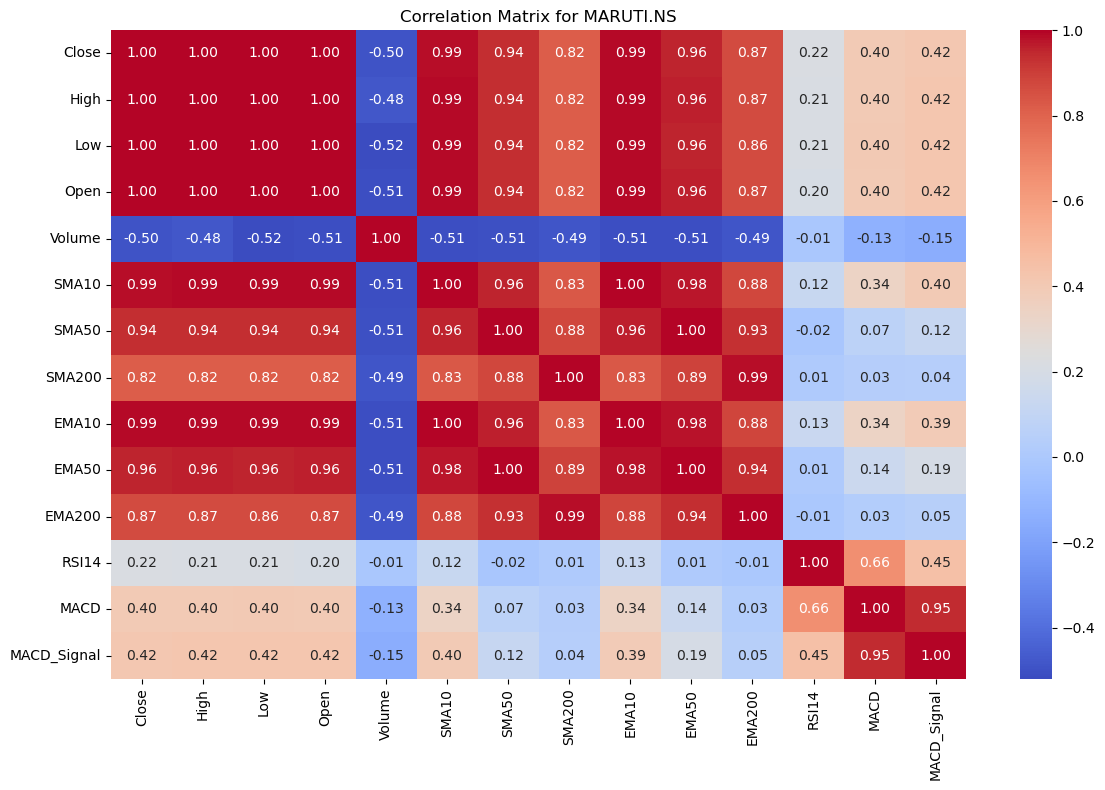

Top features correlated with 'Close' for MARUTI.NS:
High           0.998515
Low            0.998113
Open           0.995912
EMA10          0.991305
SMA10          0.987158
EMA50          0.957782
SMA50          0.937302
EMA200         0.865311
SMA200         0.818571
MACD_Signal    0.417436
MACD           0.397864
RSI14          0.220088
Volume        -0.495568
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for MARUTI.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



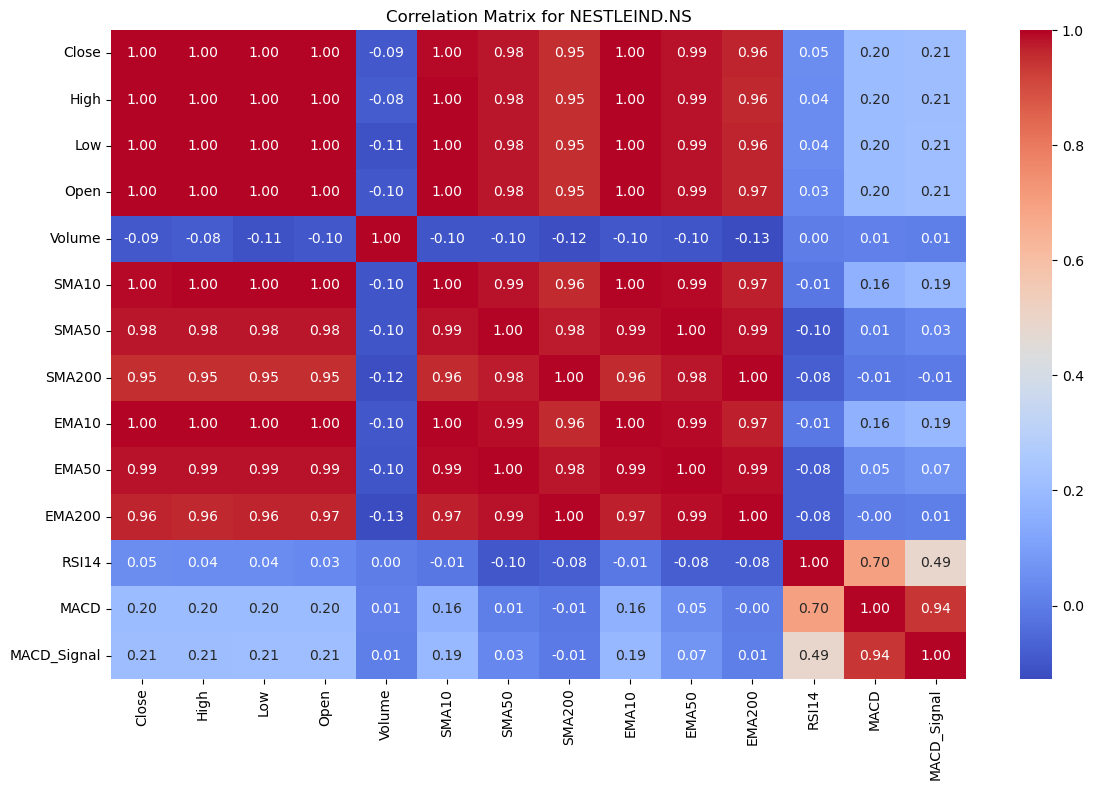

Top features correlated with 'Close' for NESTLEIND.NS:
High           0.999324
Low            0.999156
Open           0.998286
EMA10          0.996852
SMA10          0.995455
EMA50          0.985650
SMA50          0.979384
EMA200         0.964775
SMA200         0.953233
MACD_Signal    0.205814
MACD           0.200232
RSI14          0.048358
Volume        -0.094878
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for NESTLEIND.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



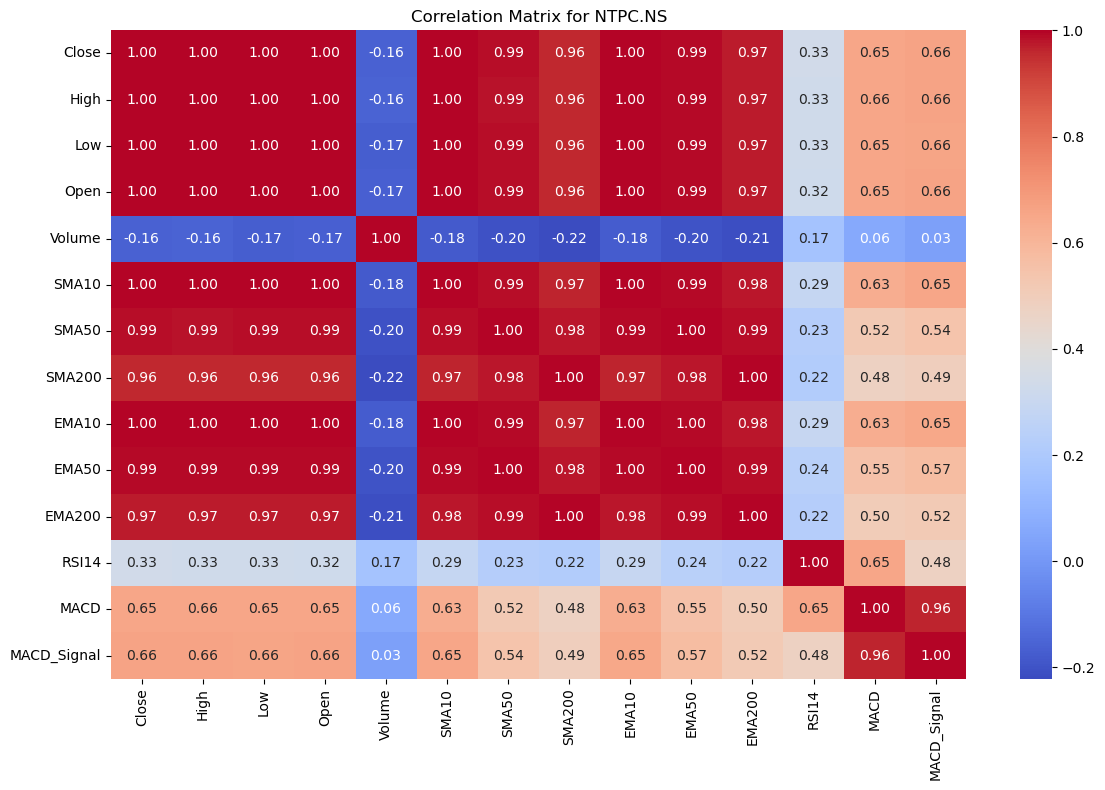

Top features correlated with 'Close' for NTPC.NS:
High           0.999678
Low            0.999601
Open           0.999122
EMA10          0.998098
SMA10          0.997303
EMA50          0.990674
SMA50          0.985769
EMA200         0.973876
SMA200         0.960801
MACD_Signal    0.661248
MACD           0.653147
RSI14          0.332131
Volume        -0.160810
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for NTPC.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



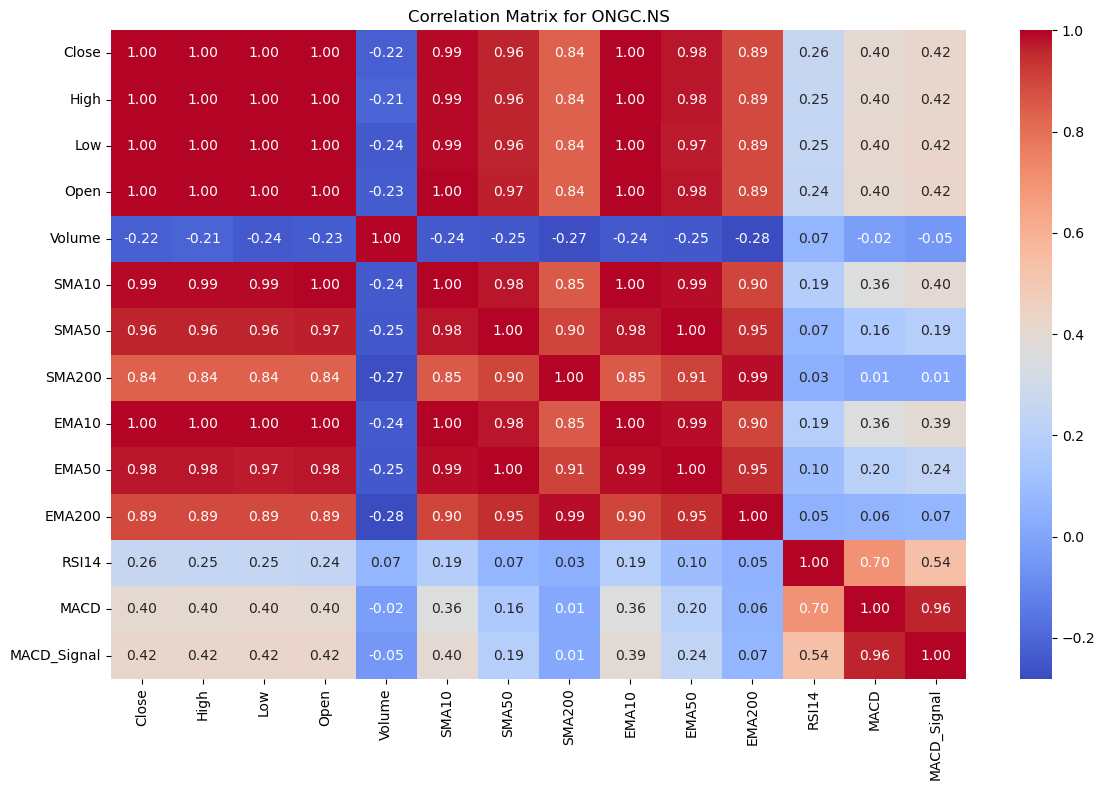

Top features correlated with 'Close' for ONGC.NS:
Low            0.999229
High           0.999135
Open           0.998189
EMA10          0.995882
SMA10          0.994172
EMA50          0.975004
SMA50          0.964453
EMA200         0.890781
SMA200         0.838951
MACD_Signal    0.418903
MACD           0.402421
RSI14          0.256359
Volume        -0.224244
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ONGC.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



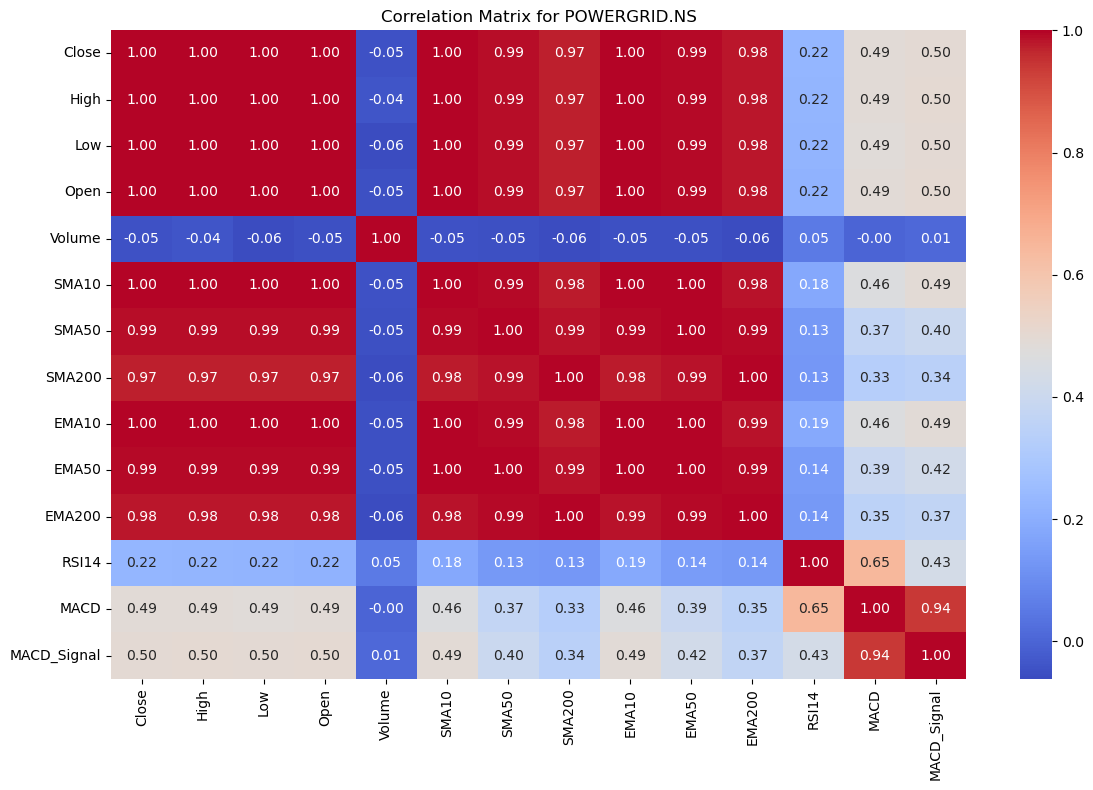

Top features correlated with 'Close' for POWERGRID.NS:
High           0.999529
Low            0.999506
Open           0.998829
EMA10          0.998165
SMA10          0.997238
EMA50          0.993197
SMA50          0.990715
EMA200         0.981169
SMA200         0.971937
MACD_Signal    0.498097
MACD           0.487044
RSI14          0.224939
Volume        -0.047408
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for POWERGRID.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



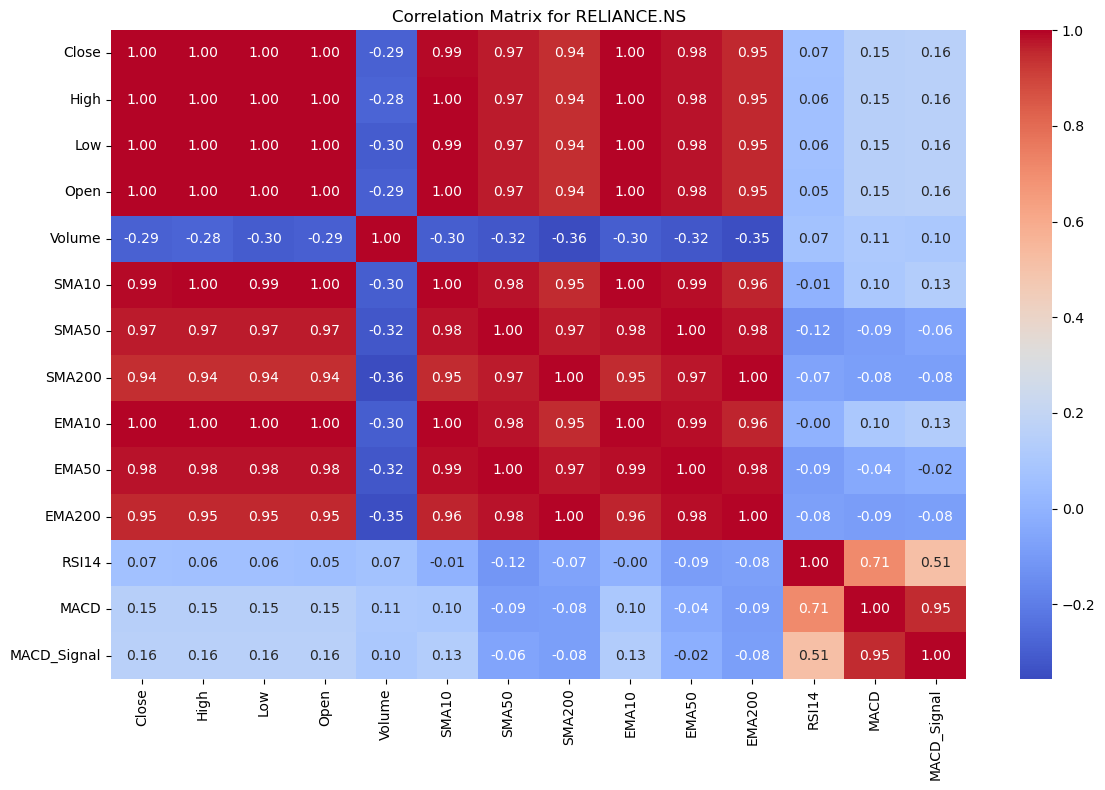

Top features correlated with 'Close' for RELIANCE.NS:
High           0.999376
Low            0.999325
Open           0.998368
EMA10          0.996007
SMA10          0.994355
EMA50          0.979168
SMA50          0.970067
EMA200         0.953544
SMA200         0.942820
MACD_Signal    0.155004
MACD           0.149525
RSI14          0.065375
Volume        -0.289535
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for RELIANCE.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



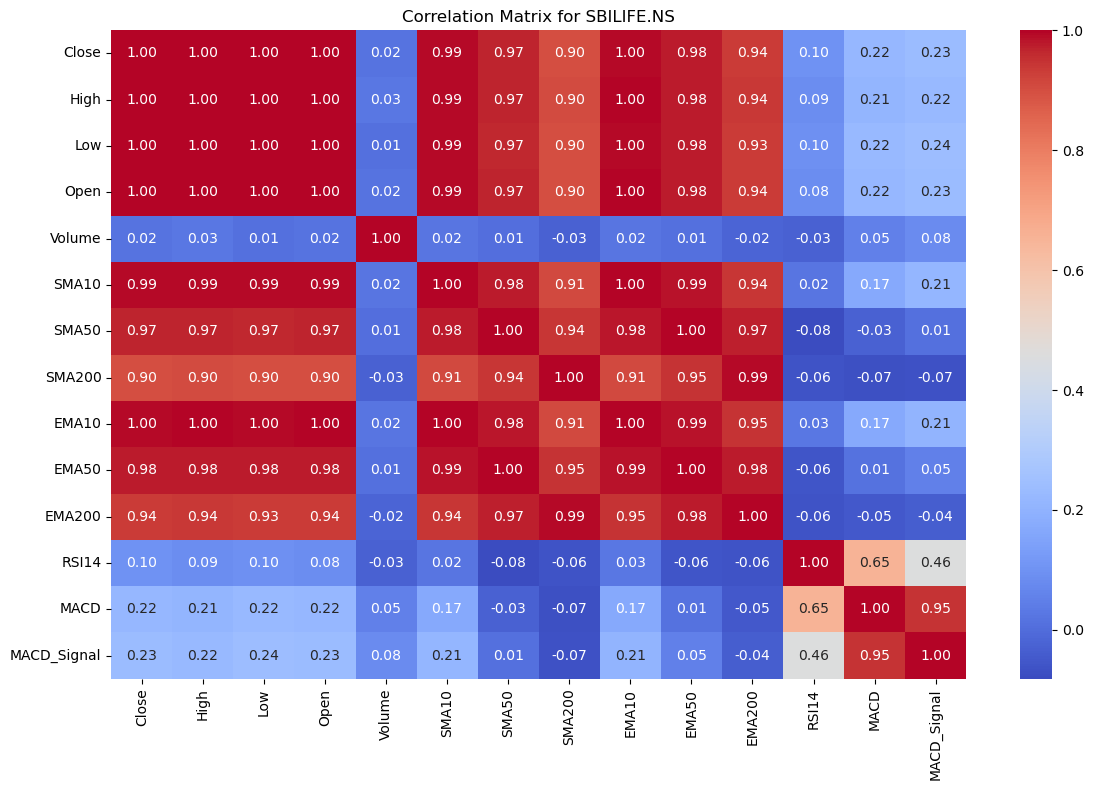

Top features correlated with 'Close' for SBILIFE.NS:
High           0.999019
Low            0.998938
Open           0.997874
EMA10          0.995465
SMA10          0.993550
EMA50          0.976427
SMA50          0.967241
EMA200         0.936067
SMA200         0.901299
MACD_Signal    0.231626
MACD           0.215778
RSI14          0.096026
Volume         0.018691
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for SBILIFE.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



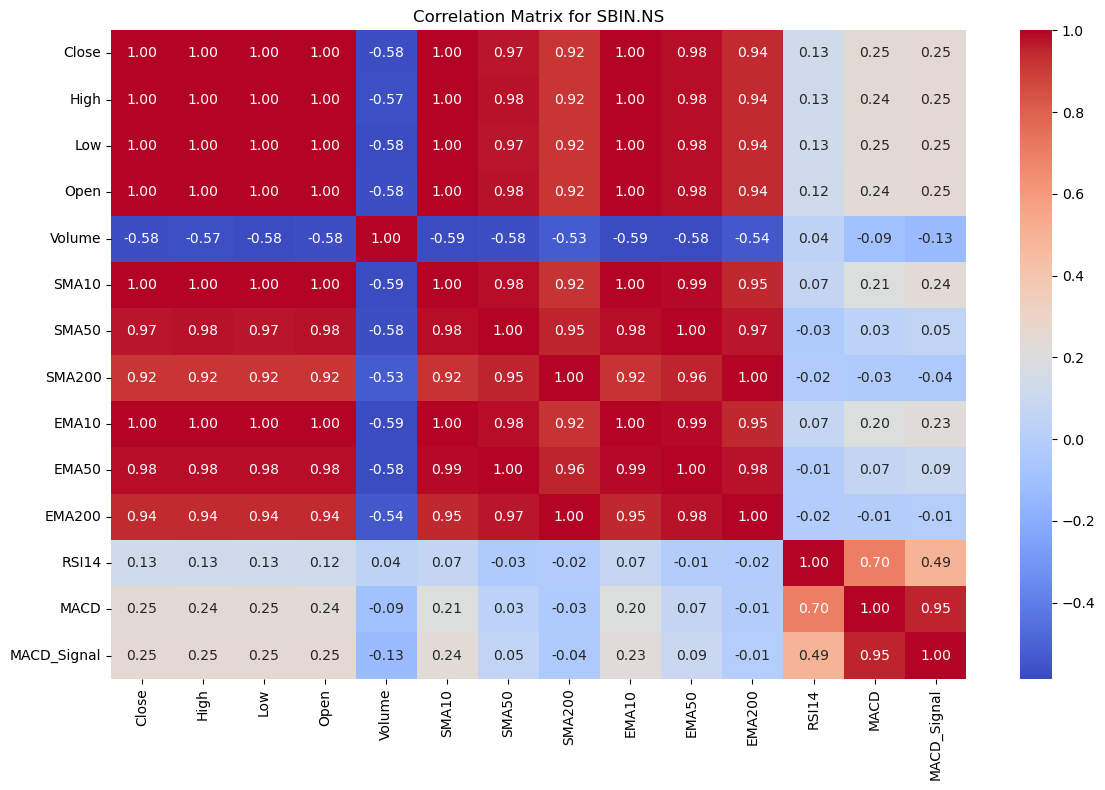

Top features correlated with 'Close' for SBIN.NS:
High           0.999534
Low            0.999486
Open           0.998876
EMA10          0.996865
SMA10          0.995628
EMA50          0.982014
SMA50          0.974608
EMA200         0.941303
SMA200         0.915848
MACD_Signal    0.253527
MACD           0.246307
RSI14          0.131550
Volume        -0.575549
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for SBIN.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



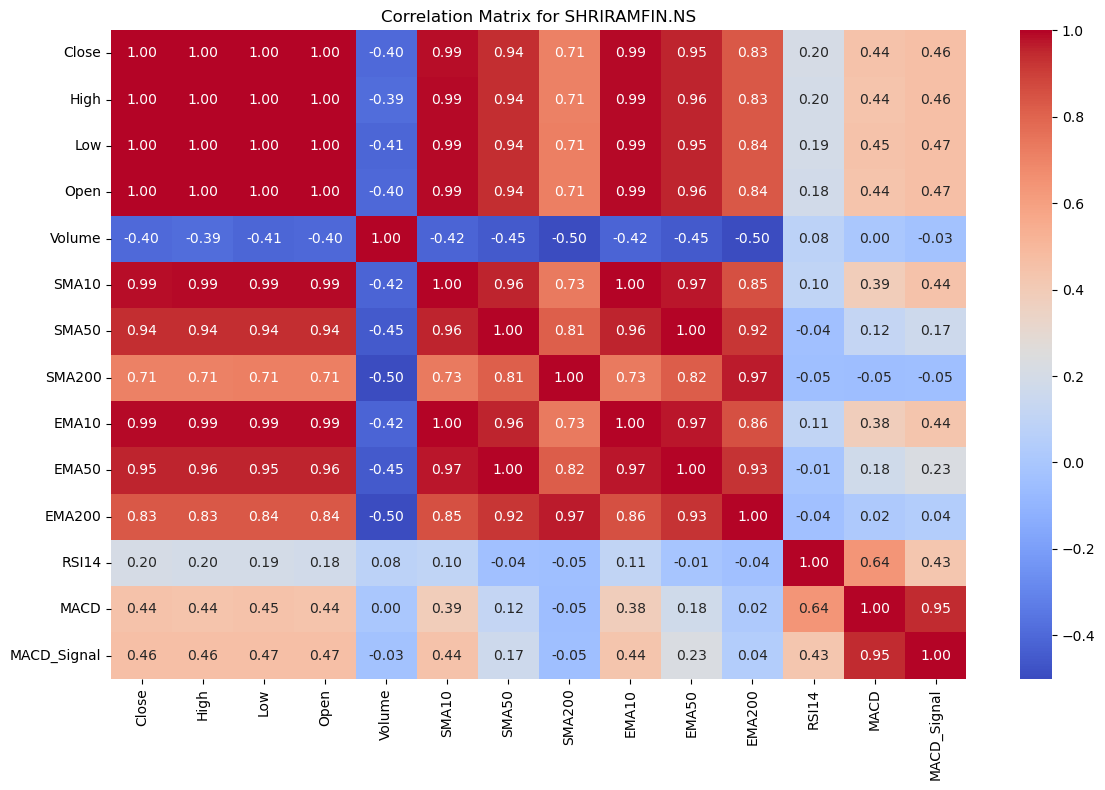

Top features correlated with 'Close' for SHRIRAMFIN.NS:
Low            0.998483
High           0.998448
Open           0.996292
EMA10          0.991101
SMA10          0.987469
EMA50          0.953712
SMA50          0.935964
EMA200         0.833418
SMA200         0.711585
MACD_Signal    0.462295
MACD           0.444048
RSI14          0.203555
Volume        -0.396294
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for SHRIRAMFIN.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



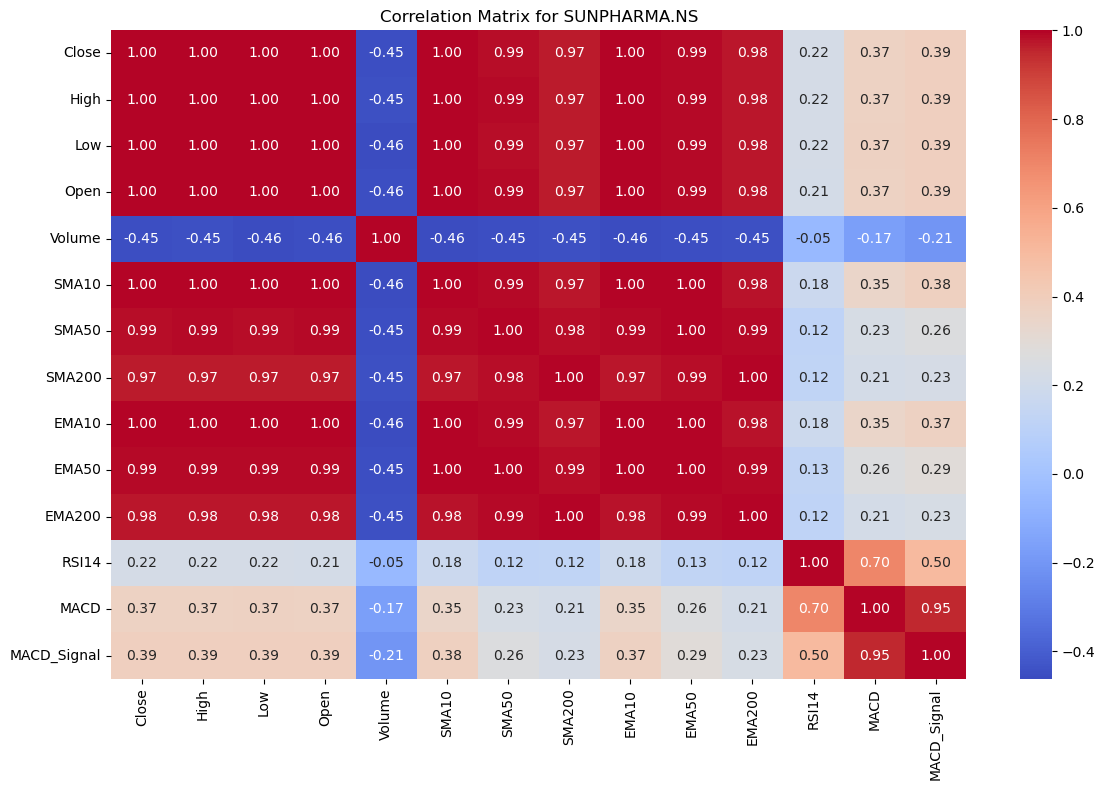

Top features correlated with 'Close' for SUNPHARMA.NS:
High           0.999688
Low            0.999619
Open           0.999187
EMA10          0.998406
SMA10          0.997714
EMA50          0.992119
SMA50          0.988483
EMA200         0.976055
SMA200         0.970664
MACD_Signal    0.387208
MACD           0.371825
RSI14          0.221097
Volume        -0.452921
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for SUNPHARMA.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



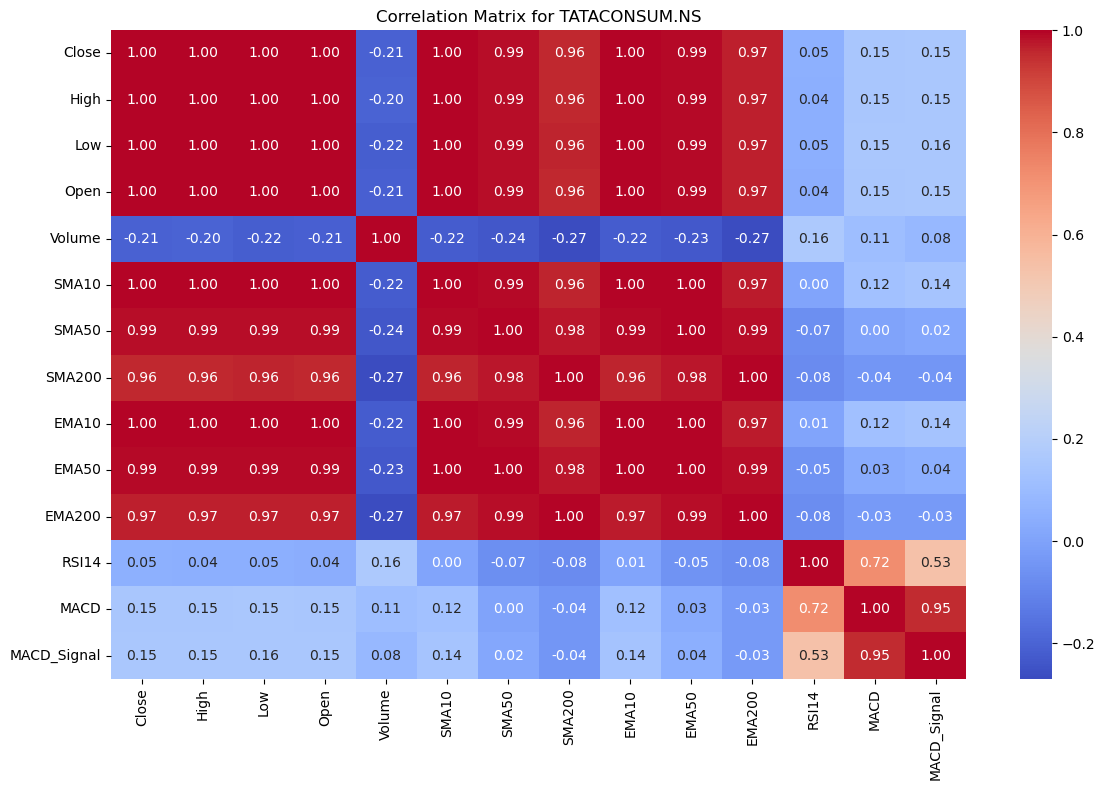

Top features correlated with 'Close' for TATACONSUM.NS:
High           0.999691
Low            0.999671
Open           0.999231
EMA10          0.998444
SMA10          0.997856
EMA50          0.991482
SMA50          0.988075
EMA200         0.969277
SMA200         0.960207
MACD_Signal    0.154079
MACD           0.151625
RSI14          0.048626
Volume        -0.207749
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TATACONSUM.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



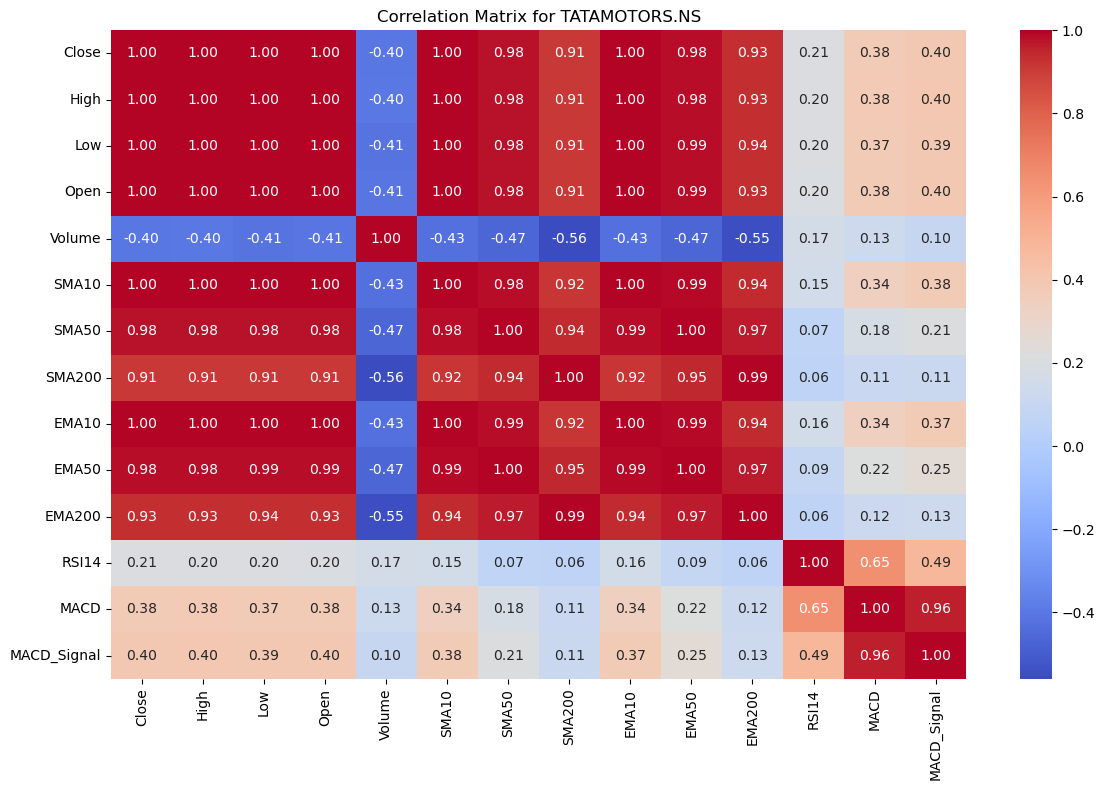

Top features correlated with 'Close' for TATAMOTORS.NS:
High           0.999705
Low            0.999647
Open           0.999210
EMA10          0.997670
SMA10          0.996808
EMA50          0.984716
SMA50          0.977862
EMA200         0.934451
SMA200         0.911163
MACD_Signal    0.396275
MACD           0.378180
RSI14          0.206432
Volume        -0.404314
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TATAMOTORS.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



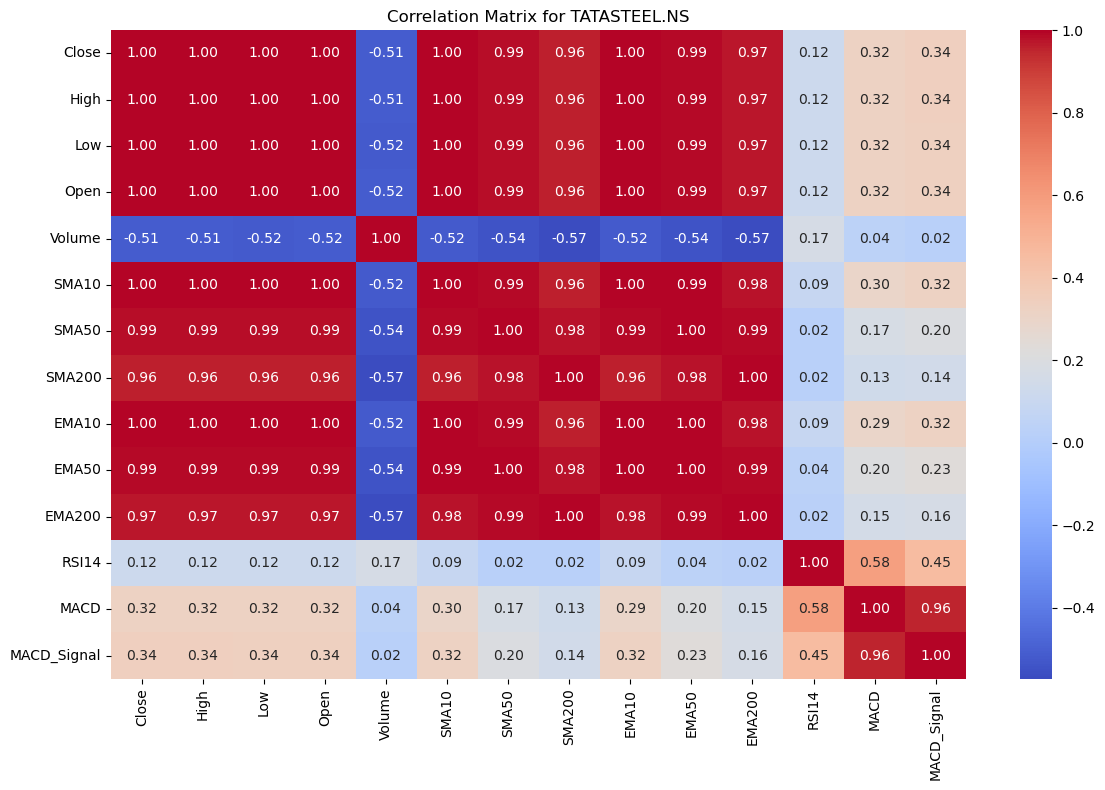

Top features correlated with 'Close' for TATASTEEL.NS:
Low            0.999864
High           0.999858
Open           0.999633
EMA10          0.998323
SMA10          0.997666
EMA50          0.991043
SMA50          0.987023
EMA200         0.973352
SMA200         0.958056
MACD_Signal    0.337148
MACD           0.323257
RSI14          0.121242
Volume        -0.513954
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TATASTEEL.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



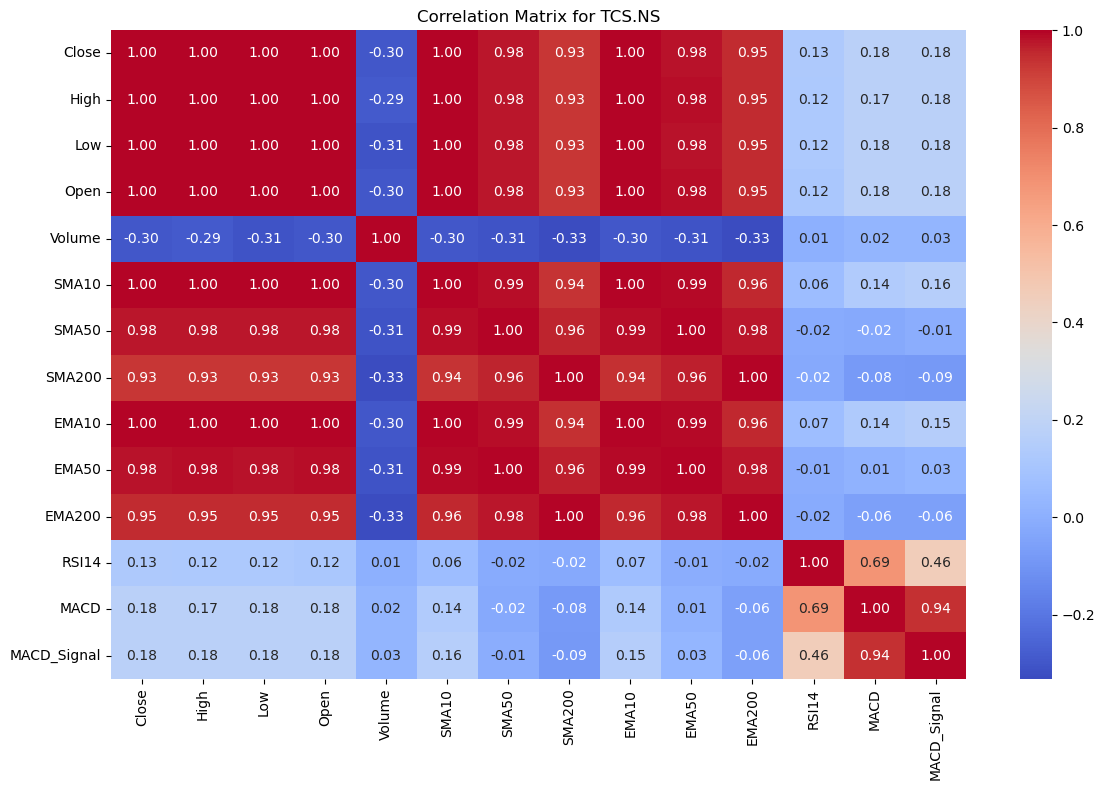

Top features correlated with 'Close' for TCS.NS:
High           0.999472
Low            0.999409
Open           0.998611
EMA10          0.996667
SMA10          0.995303
EMA50          0.984110
SMA50          0.978151
EMA200         0.948970
SMA200         0.929519
MACD           0.176606
MACD_Signal    0.175046
RSI14          0.127943
Volume        -0.296404
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TCS.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



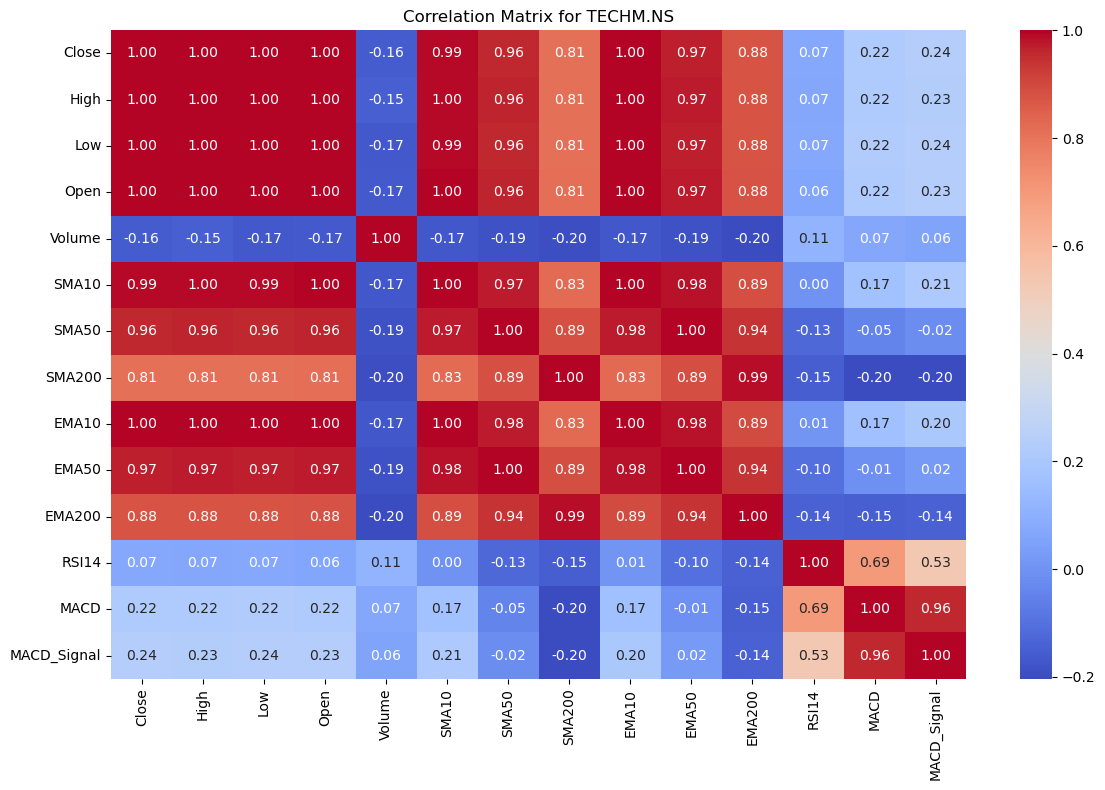

Top features correlated with 'Close' for TECHM.NS:
Low            0.999383
High           0.999362
Open           0.998521
EMA10          0.995860
SMA10          0.994313
EMA50          0.970941
SMA50          0.962008
EMA200         0.876759
SMA200         0.810974
MACD_Signal    0.235087
MACD           0.218823
RSI14          0.073221
Volume        -0.159110
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TECHM.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



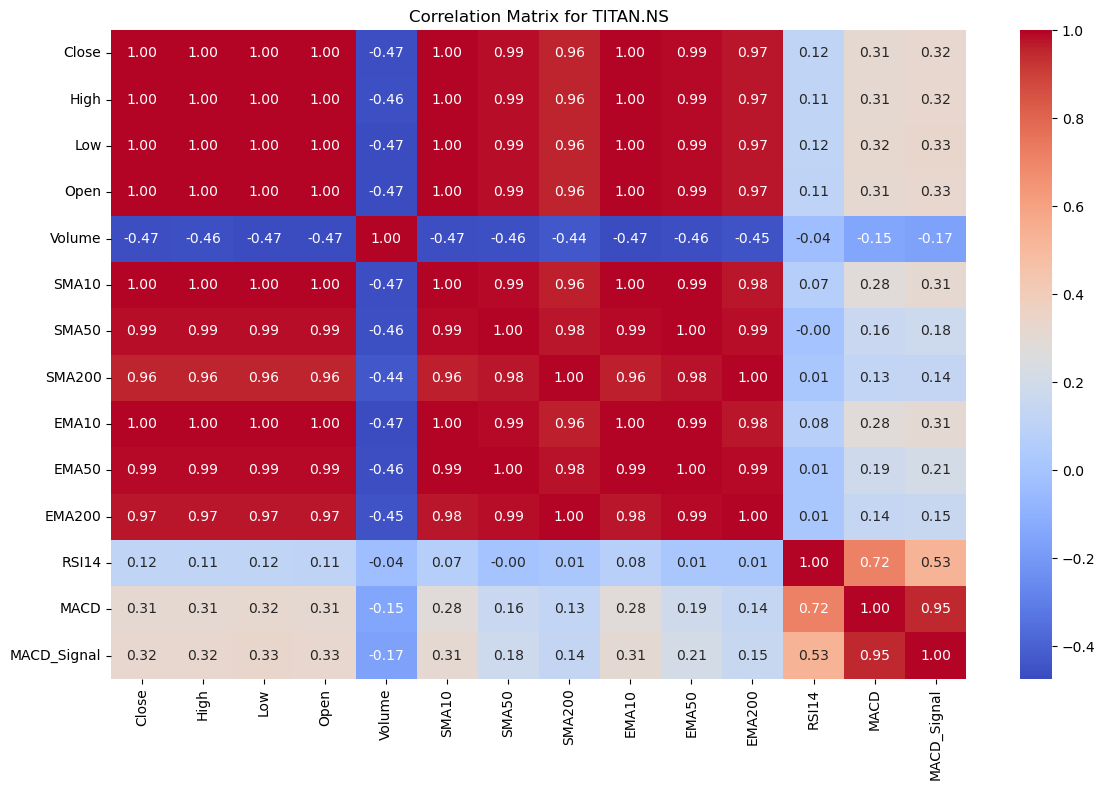

Top features correlated with 'Close' for TITAN.NS:
High           0.999726
Low            0.999695
Open           0.999295
EMA10          0.998243
SMA10          0.997453
EMA50          0.990364
SMA50          0.986402
EMA200         0.972556
SMA200         0.959450
MACD_Signal    0.324022
MACD           0.312915
RSI14          0.118864
Volume        -0.467464
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TITAN.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



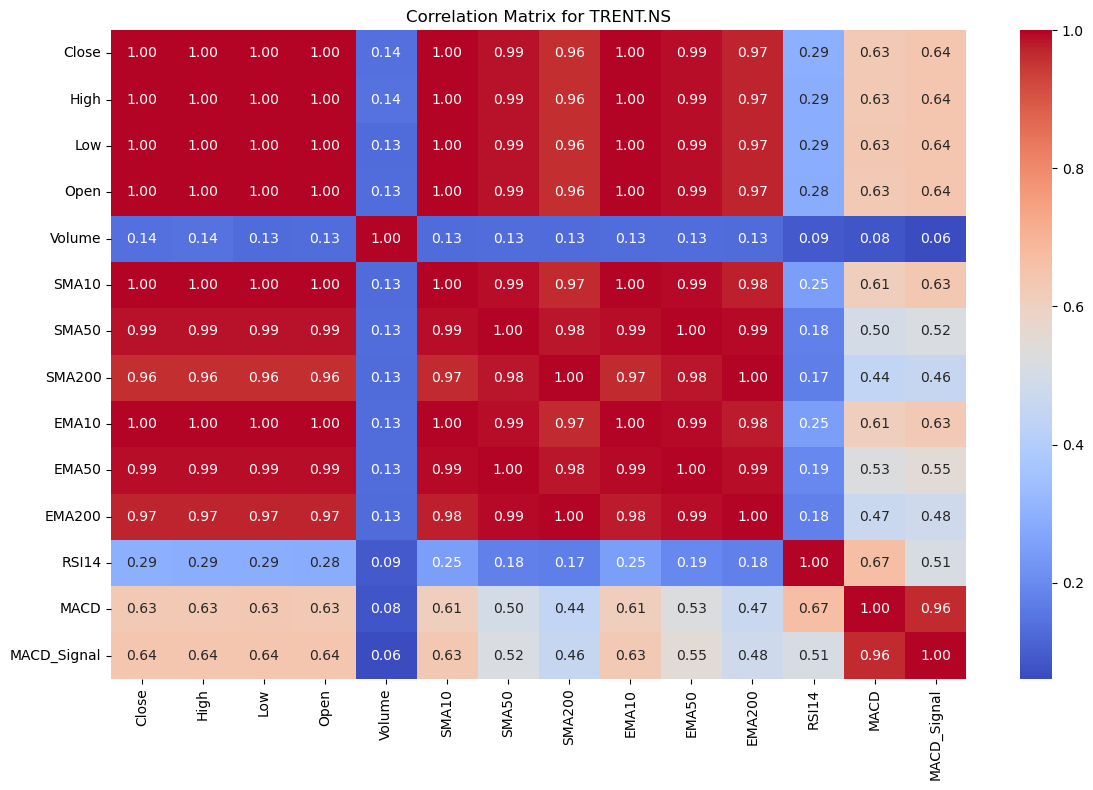

Top features correlated with 'Close' for TRENT.NS:
High           0.999728
Low            0.999612
Open           0.999299
EMA10          0.998204
SMA10          0.997448
EMA50          0.990194
SMA50          0.985485
EMA200         0.973407
SMA200         0.960994
MACD_Signal    0.641874
MACD           0.632179
RSI14          0.292283
Volume         0.138158
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for TRENT.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



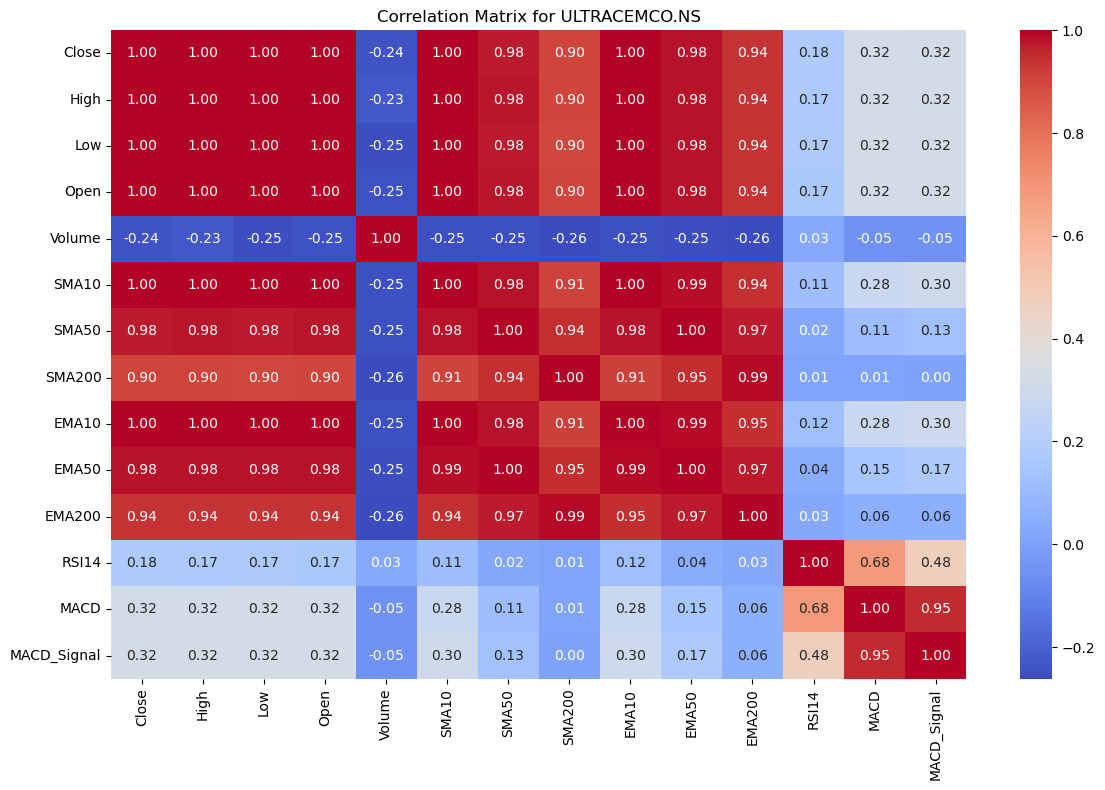

Top features correlated with 'Close' for ULTRACEMCO.NS:
High           0.999422
Low            0.999345
Open           0.998558
EMA10          0.996769
SMA10          0.995410
EMA50          0.982391
SMA50          0.975336
EMA200         0.936671
SMA200         0.901455
MACD_Signal    0.321659
MACD           0.318916
RSI14          0.177291
Volume        -0.240270
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for ULTRACEMCO.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'SMA200', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



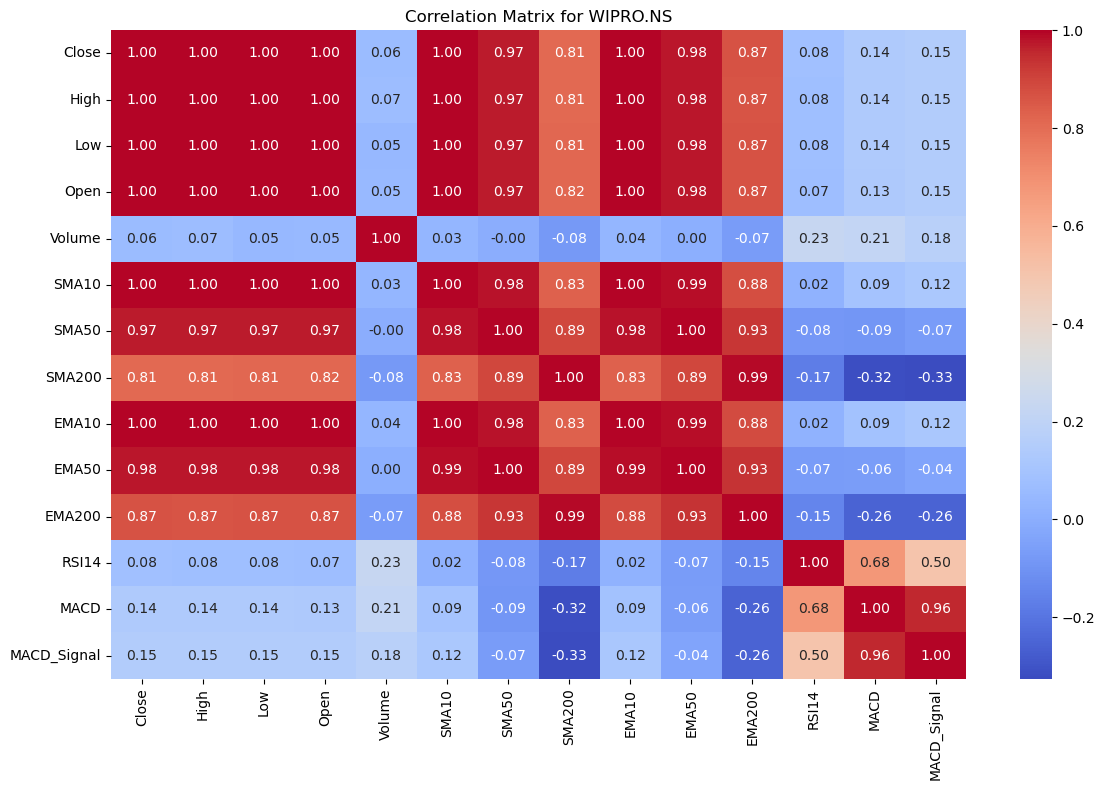

Top features correlated with 'Close' for WIPRO.NS:
High           0.999612
Low            0.999547
Open           0.999012
EMA10          0.996815
SMA10          0.995663
EMA50          0.977575
SMA50          0.972278
EMA200         0.866048
SMA200         0.813134
MACD_Signal    0.147216
MACD           0.138589
RSI14          0.080597
Volume         0.060158
Name: Close, dtype: float64

Highly correlated features (abs(corr) > 0.9) for WIPRO.NS, consider dropping: ['High', 'Low', 'Open', 'SMA10', 'SMA50', 'EMA10', 'EMA50', 'EMA200', 'MACD_Signal']



In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from glob import glob

engineered_folder = "engineered"
engineered_files = glob(os.path.join(engineered_folder, "*_engineered.csv"))

for file in engineered_files:
    company_name = os.path.basename(file).split('_')[0]
    df = pd.read_csv(file)
    if df.shape[0] == 0:
        print(f"{company_name}: DataFrame is empty, skipping.")
        continue
    # Drop Date column for correlation
    features = df.drop(columns=['Date'])
    if features.shape[0] == 0 or features.shape[1] == 0:
        print(f"{company_name}: No features for correlation, skipping.")
        continue
    # Compute correlation matrix
    corr_matrix = features.corr()
    # Plot heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
    plt.title(f'Correlation Matrix for {company_name}')
    plt.tight_layout()
    plt.show()
    
    # Find correlations with the target variable ('Close')
    if 'Close' in corr_matrix.columns:
        target_corr = corr_matrix['Close'].drop('Close').sort_values(ascending=False)
        print(f"Top features correlated with 'Close' for {company_name}:\n{target_corr}\n")
    else:
        print(f"'Close' not in correlation matrix for {company_name}.\n")
    
    # Suggest highly correlated features for possible removal
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    redundant = [column for column in upper.columns if any(upper[column].abs() > 0.9)]
    if redundant:
        print(f"Highly correlated features (abs(corr) > 0.9) for {company_name}, consider dropping: {redundant}\n")
    else:
        print("No highly redundant features found.\n")


In [3]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

train_folder = "train_split"
test_folder = "test_split"

# Example: Use first company
company_name = os.listdir(train_folder)[0].split('_')[0]

train_df = pd.read_csv(os.path.join(train_folder, f"{company_name}_train.csv"))
test_df = pd.read_csv(os.path.join(test_folder, f"{company_name}_test.csv"))

# Prepare features and target
feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
X_train = train_df[feature_cols].values
y_train = train_df['Close'].values

X_test = test_df[feature_cols].values
y_test = test_df['Close'].values

# Train Linear Regression model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict
y_pred = lr.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression results for {company_name}:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


Linear Regression results for ADANIENT.NS:
MAE: 0.0065
RMSE: 0.0094
R²: 0.9958


In [4]:
results = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    if len(feature_cols) == 0:
        continue
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)
print(results_df)


          Company       MAE      RMSE        R2
0     ADANIENT.NS  0.006527  0.009392  0.995792
1   ADANIPORTS.NS  0.004535  0.006646  0.997287
2   APOLLOHOSP.NS  0.004119  0.005129  0.996280
3   ASIANPAINT.NS  0.003725  0.004947  0.996756
4     AXISBANK.NS  0.004385  0.005587  0.996099
5   BAJAJ-AUTO.NS  0.003644  0.004920  0.999073
6   BAJAJFINSV.NS  0.003760  0.004948  0.996478
7   BAJFINANCE.NS  0.003591  0.004635  0.998040
8          BEL.NS  0.002982  0.003935  0.999125
9   BHARTIARTL.NS  0.003332  0.004733  0.997797
10       CIPLA.NS  0.004280  0.005803  0.998464
11   COALINDIA.NS  0.003195  0.004394  0.999277
12     DRREDDY.NS  0.004135  0.005313  0.998391
13   EICHERMOT.NS  0.004570  0.006092  0.995992
14      GRASIM.NS  0.003517  0.004458  0.997169
15     HCLTECH.NS  0.003540  0.004772  0.997861
16    HDFCBANK.NS  0.005020  0.006382  0.987607
17    HDFCLIFE.NS  0.005884  0.007792  0.997268
18  HEROMOTOCO.NS  0.003790  0.005028  0.998871
19    HINDALCO.NS  0.003905  0.004942  0

In [5]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

train_folder = "train_split"
test_folder = "test_split"

# Example: Use first company
company_name = os.listdir(train_folder)[0].split('_')[0]

train_df = pd.read_csv(os.path.join(train_folder, f"{company_name}_train.csv"))
test_df = pd.read_csv(os.path.join(test_folder, f"{company_name}_test.csv"))

feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
X_train = train_df[feature_cols].values
y_train = train_df['Close'].values
X_test = test_df[feature_cols].values
y_test = test_df['Close'].values

# Train Decision Tree Regressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

# Predict
y_pred = dt.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Decision Tree results for {company_name}:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


Decision Tree results for ADANIENT.NS:
MAE: 0.1030
RMSE: 0.1438
R²: 0.0132


In [6]:
results_dt = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    if len(feature_cols) == 0:
        continue
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    dt = DecisionTreeRegressor(random_state=42)
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results_dt.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_dt_df = pd.DataFrame(results_dt)
print(results_dt_df)


          Company       MAE      RMSE        R2
0     ADANIENT.NS  0.103037  0.143824  0.013233
1   ADANIPORTS.NS  0.018909  0.034894  0.925208
2   APOLLOHOSP.NS  0.012531  0.018097  0.953684
3   ASIANPAINT.NS  0.008900  0.011025  0.983884
4     AXISBANK.NS  0.050559  0.074572  0.304967
5   BAJAJ-AUTO.NS  0.149714  0.206459 -0.633213
6   BAJAJFINSV.NS  0.011038  0.014014  0.971755
7   BAJFINANCE.NS  0.008937  0.012795  0.985064
8          BEL.NS  0.097240  0.140629 -0.117928
9   BHARTIARTL.NS  0.054582  0.085260  0.284881
10       CIPLA.NS  0.032822  0.048191  0.894050
11   COALINDIA.NS  0.098808  0.179049 -0.201572
12     DRREDDY.NS  0.020306  0.032714  0.938979
13   EICHERMOT.NS  0.019731  0.032777  0.883964
14      GRASIM.NS  0.026577  0.047306  0.681178
15     HCLTECH.NS  0.023367  0.049421  0.770572
16    HDFCBANK.NS  0.021012  0.030329  0.720123
17    HDFCLIFE.NS  0.012203  0.016706  0.987441
18  HEROMOTOCO.NS  0.027717  0.067175  0.798368
19    HINDALCO.NS  0.007712  0.010348  0

In [7]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Paths
train_seq_folder = "train_seq"
test_seq_folder = "test_seq"

# Example: Use first company
company_file = os.listdir(train_seq_folder)[0]
company_name = company_file.split('_')[0]

# Load windowed train/test data
train_data = np.load(os.path.join(train_seq_folder, f"{company_name}_train_seq.npz"))
test_data = np.load(os.path.join(test_seq_folder, f"{company_name}_test_seq.npz"))
X_train, y_train = train_data['X'], train_data['y']
X_test, y_test = test_data['X'], test_data['y']

# Model definition
model = Sequential([
    LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

# Fit model
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test), verbose=2)

# Predict
y_pred = model.predict(X_test).flatten()

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"LSTM results for {company_name}:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


Epoch 1/30
32/32 - 2s - loss: 0.3109 - val_loss: 0.0979 - 2s/epoch - 65ms/step
Epoch 2/30
32/32 - 0s - loss: 0.1823 - val_loss: 0.0345 - 213ms/epoch - 7ms/step
Epoch 3/30
32/32 - 0s - loss: 0.1383 - val_loss: 0.0196 - 209ms/epoch - 7ms/step
Epoch 4/30
32/32 - 0s - loss: 0.0901 - val_loss: 0.0195 - 218ms/epoch - 7ms/step
Epoch 5/30
32/32 - 0s - loss: 0.0647 - val_loss: 0.0177 - 218ms/epoch - 7ms/step
Epoch 6/30
32/32 - 0s - loss: 0.0380 - val_loss: 0.0170 - 240ms/epoch - 7ms/step
Epoch 7/30
32/32 - 0s - loss: 0.0248 - val_loss: 0.0116 - 228ms/epoch - 7ms/step
Epoch 8/30
32/32 - 0s - loss: 0.0142 - val_loss: 0.0143 - 210ms/epoch - 7ms/step
Epoch 9/30
32/32 - 0s - loss: 0.0116 - val_loss: 0.0070 - 223ms/epoch - 7ms/step
Epoch 10/30
32/32 - 0s - loss: 0.0098 - val_loss: 0.0113 - 234ms/epoch - 7ms/step
Epoch 11/30
32/32 - 0s - loss: 0.0094 - val_loss: 0.0171 - 223ms/epoch - 7ms/step
Epoch 12/30
32/32 - 0s - loss: 0.0077 - val_loss: 0.0081 - 225ms/epoch - 7ms/step
Epoch 13/30
32/32 - 0s - lo

In [8]:
lstm_results = []

for company_file in os.listdir(train_seq_folder):
    company_name = company_file.split('_')[0]
    train_data_path = os.path.join(train_seq_folder, f"{company_name}_train_seq.npz")
    test_data_path = os.path.join(test_seq_folder, f"{company_name}_test_seq.npz")
    if not (os.path.exists(train_data_path) and os.path.exists(test_data_path)):
        continue
    train_data = np.load(train_data_path)
    test_data = np.load(test_data_path)
    X_train, y_train = train_data['X'], train_data['y']
    X_test, y_test = test_data['X'], test_data['y']
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    # New model for each company
    model = Sequential([
        LSTM(50, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    model.fit(X_train, y_train, epochs=30, batch_size=32, verbose=0)
    y_pred = model.predict(X_test).flatten()
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    lstm_results.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })
    print(f"{company_name}: MAE={mae:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}")

lstm_results_df = pd.DataFrame(lstm_results)
print(lstm_results_df)


8/8 [==============================] - 0s 2ms/step
ADANIENT.NS: MAE=0.0647, RMSE=0.0820, R2=0.1815
8/8 [==============================] - 0s 4ms/step
ADANIPORTS.NS: MAE=0.0321, RMSE=0.0479, R2=0.8706
8/8 [==============================] - 0s 3ms/step
APOLLOHOSP.NS: MAE=0.0534, RMSE=0.0624, R2=0.4448
8/8 [==============================] - 0s 3ms/step
ASIANPAINT.NS: MAE=0.0263, RMSE=0.0326, R2=0.8670
8/8 [==============================] - 0s 2ms/step
AXISBANK.NS: MAE=0.0832, RMSE=0.0979, R2=-0.0727
8/8 [==============================] - 0s 3ms/step
BAJAJ-AUTO.NS: MAE=0.0942, RMSE=0.1202, R2=0.3623
8/8 [==============================] - 0s 2ms/step
BAJAJFINSV.NS: MAE=0.0246, RMSE=0.0315, R2=0.8637
8/8 [==============================] - 0s 3ms/step
BAJFINANCE.NS: MAE=0.0149, RMSE=0.0195, R2=0.9646
8/8 [==============================] - 0s 4ms/step
BEL.NS: MAE=0.1123, RMSE=0.1366, R2=-0.0612
8/8 [==============================] - 0s 3ms/step
BHARTIARTL.NS: MAE=0.0459, RMSE=0.0586, R2=0.6748

In [9]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

train_folder = "train_split"
test_folder = "test_split"

# Example: Use first company
company_name = os.listdir(train_folder)[0].split('_')[0]

train_df = pd.read_csv(os.path.join(train_folder, f"{company_name}_train.csv"))
test_df = pd.read_csv(os.path.join(test_folder, f"{company_name}_test.csv"))

feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
X_train = train_df[feature_cols].values
y_train = train_df['Close'].values
X_test = test_df[feature_cols].values
y_test = test_df['Close'].values

# Train Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predict
y_pred = rf.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Random Forest results for {company_name}:")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


Random Forest results for ADANIENT.NS:
MAE: 0.0628
RMSE: 0.0778
R²: 0.7116


In [10]:
results_rf = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    if len(feature_cols) == 0:
        continue
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results_rf.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_rf_df = pd.DataFrame(results_rf)
print(results_rf_df)


          Company       MAE      RMSE        R2
0     ADANIENT.NS  0.062751  0.077758  0.711570
1   ADANIPORTS.NS  0.016860  0.034022  0.928900
2   APOLLOHOSP.NS  0.010095  0.016740  0.960369
3   ASIANPAINT.NS  0.005851  0.007376  0.992786
4     AXISBANK.NS  0.057395  0.084081  0.116416
5   BAJAJ-AUTO.NS  0.145123  0.201724 -0.559167
6   BAJAJFINSV.NS  0.007021  0.009059  0.988197
7   BAJFINANCE.NS  0.006891  0.010443  0.990050
8          BEL.NS  0.097880  0.142894 -0.154221
9   BHARTIARTL.NS  0.053228  0.084245  0.301807
10       CIPLA.NS  0.035310  0.052946  0.872113
11   COALINDIA.NS  0.098504  0.179609 -0.209096
12     DRREDDY.NS  0.015117  0.026348  0.960419
13   EICHERMOT.NS  0.019702  0.033830  0.876389
14      GRASIM.NS  0.023242  0.043596  0.729223
15     HCLTECH.NS  0.024401  0.053062  0.735519
16    HDFCBANK.NS  0.014572  0.022509  0.845846
17    HDFCLIFE.NS  0.007542  0.010088  0.995421
18  HEROMOTOCO.NS  0.025770  0.066678  0.801339
19    HINDALCO.NS  0.005547  0.007266  0

In [18]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

train_folder = "train_split"
test_folder = "test_split"

results_xgb = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    if len(feature_cols) == 0:
        continue
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    xgb = XGBRegressor(n_estimators=100, random_state=42)
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results_xgb.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_xgb_df = pd.DataFrame(results_xgb)
print(results_xgb_df)


          Company       MAE      RMSE        R2
0     ADANIENT.NS  0.012696  0.019751  0.981391
1   ADANIPORTS.NS  0.016357  0.031486  0.939104
2   APOLLOHOSP.NS  0.017384  0.025038  0.911339
3   ASIANPAINT.NS  0.007658  0.009569  0.987860
4     AXISBANK.NS  0.052375  0.079123  0.217553
5   BAJAJ-AUTO.NS  0.152011  0.208706 -0.668969
6   BAJAJFINSV.NS  0.009248  0.011995  0.979307
7   BAJFINANCE.NS  0.009784  0.015161  0.979029
8          BEL.NS  0.097905  0.141993 -0.139717
9   BHARTIARTL.NS  0.055365  0.085745  0.276715
10       CIPLA.NS  0.038265  0.057547  0.848918
11   COALINDIA.NS  0.100482  0.179436 -0.206773
12     DRREDDY.NS  0.020920  0.036926  0.922256
13   EICHERMOT.NS  0.025490  0.041495  0.814022
14      GRASIM.NS  0.029672  0.048798  0.660752
15     HCLTECH.NS  0.027178  0.054154  0.724520
16    HDFCBANK.NS  0.034079  0.045999  0.356206
17    HDFCLIFE.NS  0.009005  0.011922  0.993604
18  HEROMOTOCO.NS  0.026918  0.068235  0.791954
19    HINDALCO.NS  0.007813  0.010560  0

In [20]:
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os

train_folder = "train_split"
test_folder = "test_split"

results_lgb = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    if len(feature_cols) == 0:
        continue
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue
    lgb = LGBMRegressor(n_estimators=100, random_state=42)
    lgb.fit(X_train, y_train)
    y_pred = lgb.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results_lgb.append({
        'Company': company_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

results_lgb_df = pd.DataFrame(results_lgb)
print(results_lgb_df)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000244 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 1025, number of used features: 13
[LightGBM] [Info] Start training from score 0.230993
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000110 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 1025, number of used features: 13
[LightGBM] [Info] Start training from score 0.371661
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000101 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 1025, number of used features: 13
[LightGBM] [Info] Start traini

In [21]:
import pandas as pd

summary_rows = []

# For each model, find the company with the highest R2 (best)
best_lr = results_df.loc[results_df['R2'].idxmax()]
best_dt = results_dt_df.loc[results_dt_df['R2'].idxmax()]
best_rf = results_rf_df.loc[results_rf_df['R2'].idxmax()]
best_lstm = lstm_results_df.loc[lstm_results_df['R2'].idxmax()]
best_xgb = results_xgb_df.loc[results_xgb_df['R2'].idxmax()]
best_lgb = results_lgb_df.loc[results_lgb_df['R2'].idxmax()]

summary_rows.append({
    "Model": "Linear Regression",
    "Company": best_lr['Company'],
    "Mean Absolute Error (MAE)": round(best_lr['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_lr['RMSE'], 3),
    "R-Squared Error (R²)": round(best_lr['R2'], 3)
})

summary_rows.append({
    "Model": "Decision Tree",
    "Company": best_dt['Company'],
    "Mean Absolute Error (MAE)": round(best_dt['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_dt['RMSE'], 3),
    "R-Squared Error (R²)": round(best_dt['R2'], 3)
})

summary_rows.append({
    "Model": "Random Forest",
    "Company": best_rf['Company'],
    "Mean Absolute Error (MAE)": round(best_rf['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_rf['RMSE'], 3),
    "R-Squared Error (R²)": round(best_rf['R2'], 3)
})

summary_rows.append({
    "Model": "LSTM Networks",
    "Company": best_lstm['Company'],
    "Mean Absolute Error (MAE)": round(best_lstm['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_lstm['RMSE'], 3),
    "R-Squared Error (R²)": round(best_lstm['R2'], 3)
})

summary_rows.append({
    "Model": "XGBoost",
    "Company": best_xgb['Company'],
    "Mean Absolute Error (MAE)": round(best_xgb['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_xgb['RMSE'], 3),
    "R-Squared Error (R²)": round(best_xgb['R2'], 3)
})

summary_rows.append({
    "Model": "LightGBM",
    "Company": best_lgb['Company'],
    "Mean Absolute Error (MAE)": round(best_lgb['MAE'], 3),
    "Root Mean Squared Error (RMSE)": round(best_lgb['RMSE'], 3),
    "R-Squared Error (R²)": round(best_lgb['R2'], 3)
})

summary_table = pd.DataFrame(summary_rows)
display(summary_table)


,Model,Company,Mean Absolute Error (MAE),Root Mean Squared Error (RMSE),R-Squared Error (R²)
0,Linear Regression,TRENT.NS,0.003,0.005,0.999
1,Decision Tree,INDUSINDBK.NS,0.008,0.010,0.988
2,Random Forest,HDFCLIFE.NS,0.008,0.010,0.995
3,LSTM Networks,BAJFINANCE.NS,0.015,0.019,0.965
4,XGBoost,HDFCLIFE.NS,0.009,0.012,0.994
5,LightGBM,INDUSINDBK.NS,0.005,0.007,0.995


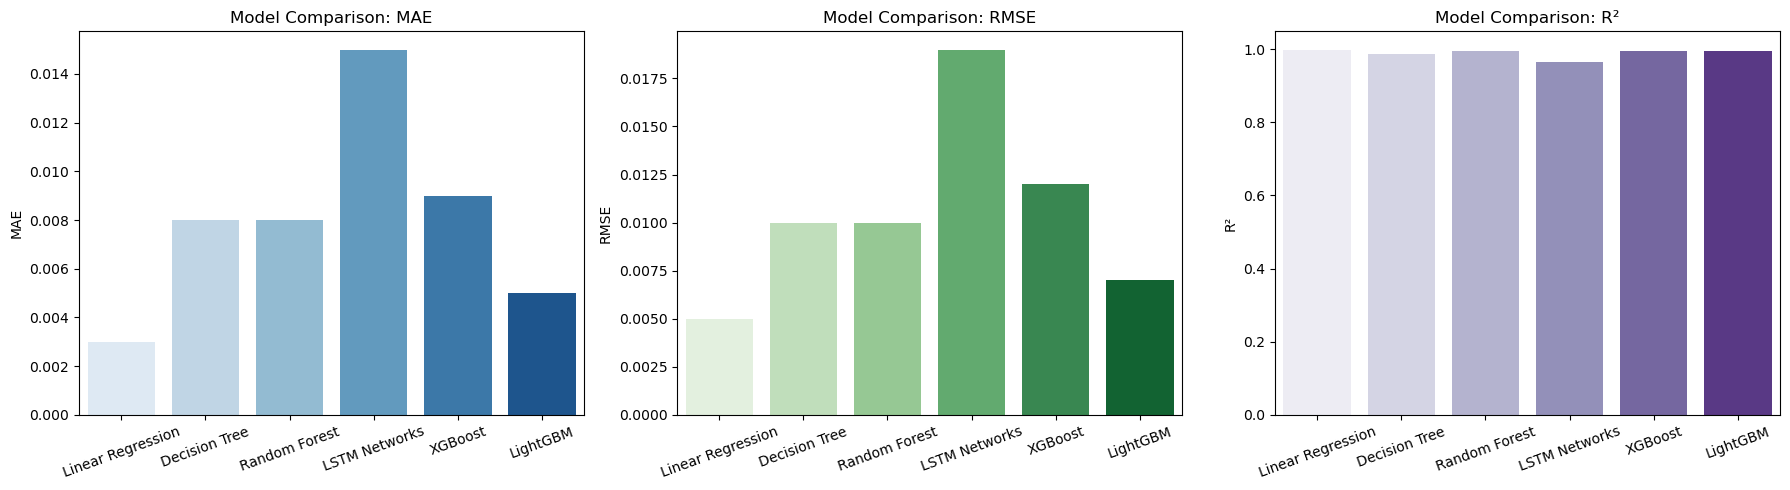

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Make sure summary_table includes all models (including XGBoost and LightGBM)

plt.figure(figsize=(18, 5))

# Plot MAE
plt.subplot(1, 3, 1)
sns.barplot(x='Model', y='Mean Absolute Error (MAE)', data=summary_table, palette='Blues')
plt.title('Model Comparison: MAE')
plt.xlabel('')
plt.ylabel('MAE')
plt.xticks(rotation=20)

# Plot RMSE
plt.subplot(1, 3, 2)
sns.barplot(x='Model', y='Root Mean Squared Error (RMSE)', data=summary_table, palette='Greens')
plt.title('Model Comparison: RMSE')
plt.xlabel('')
plt.ylabel('RMSE')
plt.xticks(rotation=20)

# Plot R²
plt.subplot(1, 3, 3)
sns.barplot(x='Model', y='R-Squared Error (R²)', data=summary_table, palette='Purples')
plt.title('Model Comparison: R²')
plt.xlabel('')
plt.ylabel('R²')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


In [23]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Copy the summary table to avoid changing original
metrics_df = summary_table.copy()

# Normalize MAE and RMSE (smaller is better, so we'll invert them later)
scaler = MinMaxScaler()
metrics_df['MAE_norm'] = scaler.fit_transform(metrics_df[['Mean Absolute Error (MAE)']])
metrics_df['RMSE_norm'] = scaler.fit_transform(metrics_df[['Root Mean Squared Error (RMSE)']])
# Normalize R² (higher is better, so as is)
metrics_df['R2_norm'] = scaler.fit_transform(metrics_df[['R-Squared Error (R²)']])

# Invert MAE/RMSE so that higher is better (1 - normalized value)
metrics_df['MAE_inv'] = 1 - metrics_df['MAE_norm']
metrics_df['RMSE_inv'] = 1 - metrics_df['RMSE_norm']

# Overall score: average of inverted MAE, inverted RMSE, and R² normalized
metrics_df['Overall_Score'] = metrics_df[['MAE_inv', 'RMSE_inv', 'R2_norm']].mean(axis=1)


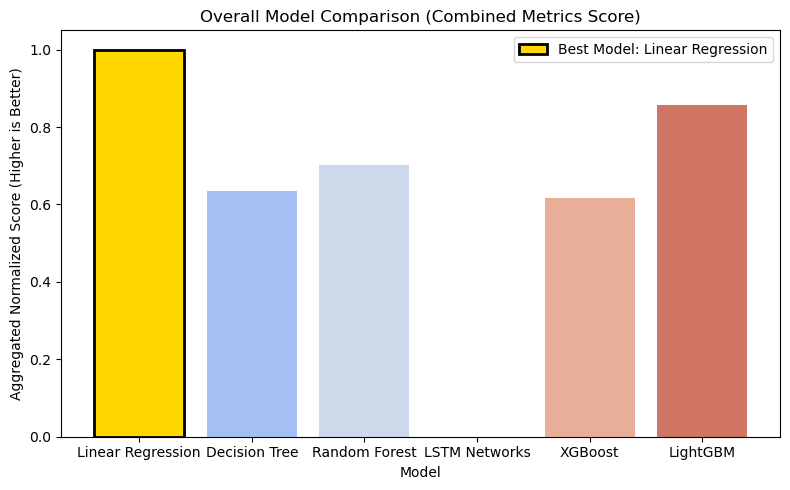


Best Overall Model: Linear Regression with Score: 1.000


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.barplot(x='Model', y='Overall_Score', data=metrics_df, palette='coolwarm')
plt.title('Overall Model Comparison (Combined Metrics Score)')
plt.ylabel('Aggregated Normalized Score (Higher is Better)')
plt.xlabel('Model')

# Highlight the best model
best_idx = metrics_df['Overall_Score'].idxmax()
best_model = metrics_df.loc[best_idx, 'Model']
best_score = metrics_df.loc[best_idx, 'Overall_Score']

plt.bar(best_model, best_score, color='gold', edgecolor='black', linewidth=2, label=f'Best Model: {best_model}')
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nBest Overall Model: {best_model} with Score: {best_score:.3f}")


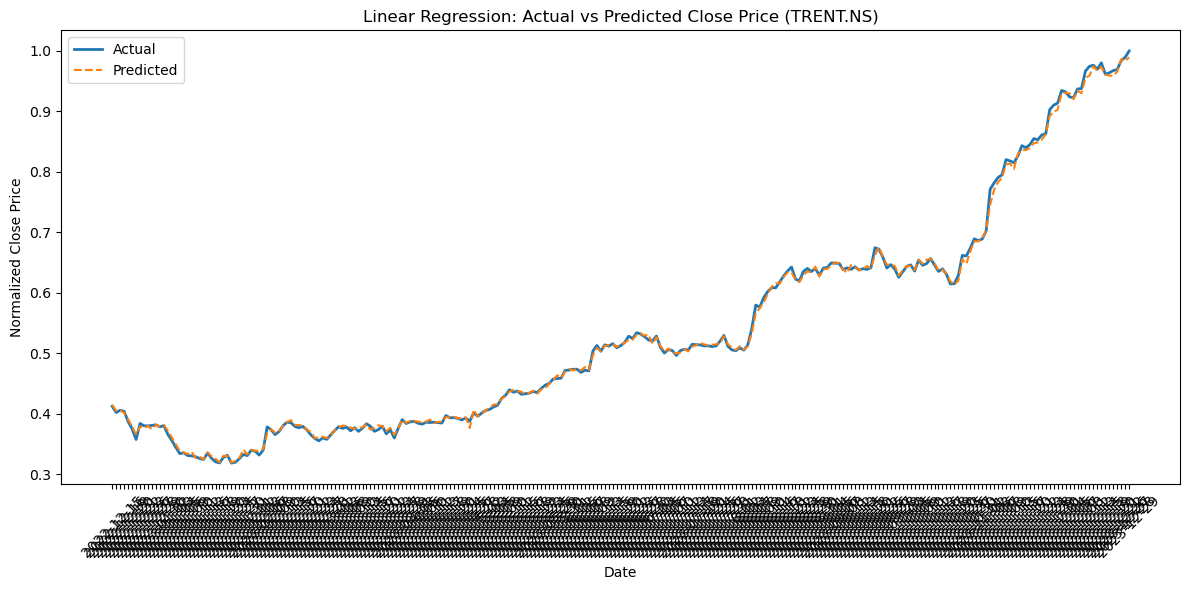

In [25]:
import matplotlib.pyplot as plt

# Example: Visualize for one company (e.g., "HDFCBANK" or use your best company)
company = best_lr['Company']

train_df = pd.read_csv(f"train_split/{company}_train.csv")
test_df = pd.read_csv(f"test_split/{company}_test.csv")
feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]

from sklearn.linear_model import LinearRegression

X_train = train_df[feature_cols].values
y_train = train_df['Close'].values
X_test = test_df[feature_cols].values
y_test = test_df['Close'].values

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

plt.figure(figsize=(12, 6))
plt.plot(test_df['Date'], y_test, label="Actual", linewidth=2)
plt.plot(test_df['Date'], y_pred, label="Predicted", linestyle='--')
plt.xlabel("Date")
plt.ylabel("Normalized Close Price")
plt.title(f"Linear Regression: Actual vs Predicted Close Price ({company})")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


        Feature  Coefficient
7         EMA10     1.037911
12  MACD_Signal    -0.747749
1           Low     0.597598
0          High     0.538627
2          Open    -0.516304
4         SMA10    -0.469749
11         MACD     0.347146
5         SMA50    -0.123058
8         EMA50    -0.120372
9        EMA200     0.118728
6        SMA200    -0.060673
3        Volume     0.000391
10        RSI14     0.000054


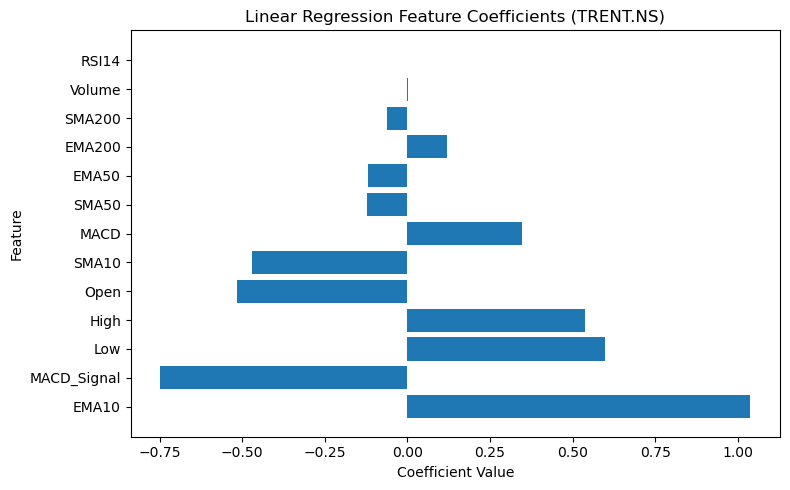

In [26]:
import pandas as pd

coefs = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print(coefs)

plt.figure(figsize=(8, 5))
plt.barh(coefs['Feature'], coefs['Coefficient'])
plt.title(f"Linear Regression Feature Coefficients ({company})")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


        Company              Model       MAE      RMSE        R2
0   ADANIENT.NS  Linear Regression  0.006527  0.009392  0.995792
0   ADANIENT.NS      Decision Tree  0.103037  0.143824  0.013233
0   ADANIENT.NS      Random Forest  0.062751  0.077758  0.711570
0   ADANIENT.NS            XGBoost  0.012696  0.019751  0.981391
0   ADANIENT.NS           LightGBM  0.010892  0.019037  0.982712
..          ...                ...       ...       ...       ...
47     WIPRO.NS      Decision Tree  0.004701  0.006314  0.969932
47     WIPRO.NS      Random Forest  0.003536  0.004640  0.983762
47     WIPRO.NS            XGBoost  0.004107  0.005089  0.980465
47     WIPRO.NS           LightGBM  0.003676  0.004602  0.984028
47     WIPRO.NS      LSTM Networks  0.030202  0.035718  0.124025

[288 rows x 5 columns]


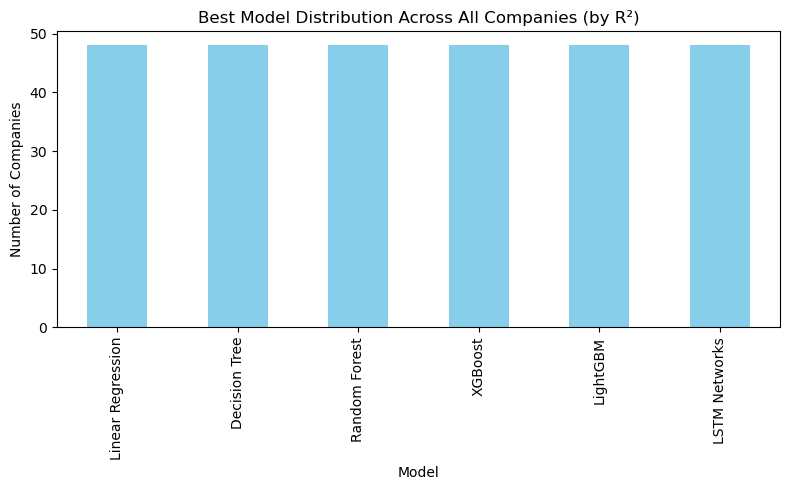

In [28]:
# Assume you have these DataFrames:
# results_lr_df, results_dt_df, results_rf_df, results_xgb_df, results_lgb_df, lstm_results_df

all_results = pd.concat([
    results_df.assign(Model="Linear Regression"),
    results_dt_df.assign(Model="Decision Tree"),
    results_rf_df.assign(Model="Random Forest"),
    results_xgb_df.assign(Model="XGBoost"),
    results_lgb_df.assign(Model="LightGBM"),
    lstm_results_df.assign(Model="LSTM Networks"),
])

# For each company, find the best model by highest R²
best_per_company = all_results.loc[all_results.groupby('Company')['R2'].idxmax()]
print(best_per_company[['Company', 'Model', 'MAE', 'RMSE', 'R2']])

plt.figure(figsize=(8, 5))
best_per_company['Model'].value_counts().plot(kind='bar', color='skyblue')
plt.title("Best Model Distribution Across All Companies (by R²)")
plt.ylabel("Number of Companies")
plt.xlabel("Model")
plt.tight_layout()
plt.show()


In [29]:
from sklearn.model_selection import GridSearchCV

# Use your data as before (example for one company)
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10]
}

rf = RandomForestRegressor(random_state=42)
grid_search = GridSearchCV(rf, param_grid, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Best RF Params:", grid_search.best_params_)
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
print("Tuned RF R2:", r2_score(y_test, y_pred))


Best RF Params: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}
Tuned RF R2: -0.18389303944597457


In [30]:
from xgboost import XGBRegressor

# Train models
lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)
xgb = XGBRegressor(n_estimators=100, random_state=42).fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)
y_pred_xgb = xgb.predict(X_test)

# Simple average ensemble
y_pred_ensemble = (y_pred_lr + y_pred_rf + y_pred_xgb) / 3

print("Ensemble R2:", r2_score(y_test, y_pred_ensemble))


Ensemble R2: 0.45772995557000173


In [31]:
import os
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score
import joblib

train_folder = "train_split"
test_folder = "test_split"
models_folder = "Models"
os.makedirs(models_folder, exist_ok=True)


In [38]:
import os
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score
import joblib

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

train_folder = "train_split"
test_folder = "test_split"
train_seq_folder = "train_seq"
test_seq_folder = "test_seq"
models_folder = "Models"
os.makedirs(models_folder, exist_ok=True)

model_classes = {
    "LinearRegression": LinearRegression,
    "DecisionTree": DecisionTreeRegressor,
    "RandomForest": RandomForestRegressor,
    "XGBoost": XGBRegressor,
    "LightGBM": LGBMRegressor
}

all_model_results = []

for train_file in os.listdir(train_folder):
    company_name = train_file.split('_')[0]
    test_file = f"{company_name}_test.csv"
    if not os.path.exists(os.path.join(test_folder, test_file)):
        continue
    train_df = pd.read_csv(os.path.join(train_folder, train_file))
    test_df = pd.read_csv(os.path.join(test_folder, test_file))
    feature_cols = [col for col in train_df.columns if col not in ['Date', 'Close']]
    X_train = train_df[feature_cols].values
    y_train = train_df['Close'].values
    X_test = test_df[feature_cols].values
    y_test = test_df['Close'].values
    if X_train.shape[0] == 0 or X_test.shape[0] == 0:
        continue

    # Sklearn/XGB/LGBM models
    for name, cls in model_classes.items():
        try:
            model = cls()
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            r2 = r2_score(y_test, y_pred)
            all_model_results.append({
                "Model": name,
                "Company": company_name,
                "R2": r2,
                "Model_Object": model
            })
        except Exception as e:
            print(f"Error with {name} for {company_name}: {e}")

    # LSTM model
    train_seq_path = os.path.join(train_seq_folder, f"{company_name}_train_seq.npz")
    test_seq_path = os.path.join(test_seq_folder, f"{company_name}_test_seq.npz")
    try:
        if os.path.exists(train_seq_path) and os.path.exists(test_seq_path):
            train_data = np.load(train_seq_path)
            test_data = np.load(test_seq_path)
            X_train_seq, y_train_seq = train_data['X'], train_data['y']
            X_test_seq, y_test_seq = test_data['X'], test_data['y']
            if X_train_seq.shape[0] > 0 and X_test_seq.shape[0] > 0:
                # Build & train LSTM
                lstm_model = Sequential([
                    LSTM(50, input_shape=(X_train_seq.shape[1], X_train_seq.shape[2]), return_sequences=False),
                    Dropout(0.2),
                    Dense(1)
                ])
                lstm_model.compile(optimizer='adam', loss='mse')
                lstm_model.fit(X_train_seq, y_train_seq, epochs=10, batch_size=32, verbose=0)
                y_pred_seq = lstm_model.predict(X_test_seq).flatten()
                r2_seq = r2_score(y_test_seq, y_pred_seq)
                all_model_results.append({
                    "Model": "LSTM",
                    "Company": company_name,
                    "R2": r2_seq,
                    "Model_Object": lstm_model
                })
    except Exception as e:
        print(f"Error with LSTM for {company_name}: {e}")

# Convert to DataFrame (remove Model_Object for summary)
results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "Model_Object"}
    for r in all_model_results
])

print(results_df.head())


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000478 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 1025, number of used features: 13
[LightGBM] [Info] Start training from score 0.230993
8/8 [==============================] - 0s 3ms/step
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000237 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Number of data points in the train set: 1025, number of used features: 13
[LightGBM] [Info] Start training from score 0.371661
8/8 [==============================] - 0s 2ms/step
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000148 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3315
[LightGBM] [Info] Nu

In [39]:
# Dictionary to hold best model info
best_models = {}

# Include LSTM explicitly in the list of all model names found in your results (in case not all are in model_classes)
all_model_names = list(set([r['Model'] for r in all_model_results]))

for model_name in all_model_names:
    # Filter for this model and find row with highest R2
    model_rows = [r for r in all_model_results if r['Model'] == model_name]
    if not model_rows:
        continue
    best_row = max(model_rows, key=lambda r: r['R2'])
    best_models[model_name] = best_row

    # Save model object to disk (using company name and model)
    if model_name == "LSTM":
        save_path = os.path.join(models_folder, f"{model_name}_{best_row['Company']}.h5")
        best_row['Model_Object'].save(save_path)
    else:
        save_path = os.path.join(models_folder, f"{model_name}_{best_row['Company']}.pkl")
        joblib.dump(best_row['Model_Object'], save_path)
    print(f"Saved {model_name} (best company: {best_row['Company']}, R²={best_row['R2']:.3f}) to {save_path}")

# Optionally, save summary of best models
summary = [{
    "Model": model,
    "Company": best_models[model]['Company'],
    "R2": best_models[model]['R2'],
    "Saved_Model_File": f"{model}_{best_models[model]['Company']}.{'h5' if model=='LSTM' else 'pkl'}"
} for model in best_models]

summary_df = pd.DataFrame(summary)
summary_csv = os.path.join(models_folder, "best_model_per_algorithm.csv")
summary_df.to_csv(summary_csv, index=False)
print("\nSaved summary CSV:", summary_csv)
display(summary_df)


Saved RandomForest (best company: INDUSINDBK.NS, R²=0.995) to Models\RandomForest_INDUSINDBK.NS.pkl
Saved LinearRegression (best company: TRENT.NS, R²=0.999) to Models\LinearRegression_TRENT.NS.pkl
Saved XGBoost (best company: HDFCLIFE.NS, R²=0.994) to Models\XGBoost_HDFCLIFE.NS.pkl
Saved LightGBM (best company: INDUSINDBK.NS, R²=0.995) to Models\LightGBM_INDUSINDBK.NS.pkl
Saved DecisionTree (best company: HDFCLIFE.NS, R²=0.987) to Models\DecisionTree_HDFCLIFE.NS.pkl
Saved LSTM (best company: HDFCLIFE.NS, R²=0.810) to Models\LSTM_HDFCLIFE.NS.h5


c:\Users\Revanth Kumar\anaconda3\lib\site-packages\keras\src\engine\training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(



Saved summary CSV: Models\best_model_per_algorithm.csv


,Model,Company,R2,Saved_Model_File
0,RandomForest,INDUSINDBK.NS,0.995129,RandomForest_INDUSINDBK.NS.pkl
1,LinearRegression,TRENT.NS,0.999339,LinearRegression_TRENT.NS.pkl
2,XGBoost,HDFCLIFE.NS,0.993604,XGBoost_HDFCLIFE.NS.pkl
3,LightGBM,INDUSINDBK.NS,0.994748,LightGBM_INDUSINDBK.NS.pkl
4,DecisionTree,HDFCLIFE.NS,0.987456,DecisionTree_HDFCLIFE.NS.pkl
5,LSTM,HDFCLIFE.NS,0.810229,LSTM_HDFCLIFE.NS.h5
